# 00b — Les méthodes usuelles des séries temporelles sur données synthétiques

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/GalaxiLir/stats-to-deeplearning/blob/main/01-ts-uncertainty/notebooks/00b_synthetic_methods.ipynb)

**Question.** Sur des séries dont la vérité est connue, qu'apporte chaque couche de modélisation usuelle (moyenne, dépendance linéaire, variance conditionnelle, régimes, tendance), et où cesse-t-elle de tenir sa promesse ? Aucune donnée réelle, aucune décision en aval : on regarde les *méthodes* et leurs *premières limites*, avant de les appliquer à Blagnac.

**Contenu.**
1. Cadre : décomposition $X_t=\mu_t+S_t$, loi prédictive, oracle (Idée 1).
2. Quatre familles de dépendance, générées puis vérifiées contre leur théorie : ARMA, GARCH, régimes de Markov, EDS (Idées 2 à 6).
3. Méthodes usuelles et métriques, dont la « largeur moyenne » (Idée 7).
4. Expériences : E1 (mémoire courte), E2 (variance conditionnelle, rupture, régimes), E3 (tendance déterministe ou aléa ; régression fallacieuse ; Idées 8 et 9).
5. Premières limites.
6. Pont vers les réseaux de neurones : pertes, plancher de l'oracle, AR(1) comme réseau récurrent linéaire (§8).

**Lire.** Les esquisses de démonstration, le dénombrement complet des familles, les références détaillées et les tableaux de résultats sont dans le [document compagnon](https://github.com/GalaxiLir/stats-to-deeplearning/blob/main/01-ts-uncertainty/docs/00b_synthetic_methods.md) (`docs/00b_synthetic_methods.md`). Les définitions préalables (stationnarité, causalité et inversibilité, conforme séparé et glissant, Newey–West, ADF et KPSS, calibration…) et les preuves longues sont dans l'[annexe technique](https://github.com/GalaxiLir/stats-to-deeplearning/blob/main/01-ts-uncertainty/docs/00b_annexe_technique.md) : les renvois « annexe P3 », « annexe T5 »… y mènent. Ici, chaque cellule de code est précédée de l'idée mathématique qu'elle teste. Les tableaux sont des moyennes sur $R$ répliques indépendantes (graine de `tsunc.config`). Durée : environ une minute en local, deux à trois sur Colab.

**Statut des références.** ✔ texte lu ; ✔ résumé lu (seul le résumé) ; ◐ fiche seule (notice bibliographique) ; ◐ ouvrage non relu ; *non vérifié* (cité de mémoire). Détail par référence : §9 du document compagnon et liste en fin de notebook.

In [1]:
# Setup. Installs what is missing: the scientific stack (preinstalled on Colab and Kaggle, absent from a bare local
# environment) and the project package `tsunc`, whose config and metrics are reused below instead of being rewritten.
import importlib
import importlib.util
import subprocess
import sys


def _pip(*args):
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *args], check=True)


_missing = [
    pkg
    for mod, pkg in (
        ("scipy", "scipy"),
        ("sklearn", "scikit-learn"),
        ("statsmodels", "statsmodels"),
    )
    if importlib.util.find_spec(mod) is None
]
if _missing:
    _pip(*_missing)
if importlib.util.find_spec("tsunc") is None:
    _pip(
        "git+https://github.com/GalaxiLir/stats-to-deeplearning.git#subdirectory=01-ts-uncertainty"
    )
importlib.invalidate_caches()

import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import optimize, signal, stats
from sklearn.linear_model import LinearRegression, QuantileRegressor
from statsmodels.regression.linear_model import OLS
from statsmodels.tsa.stattools import adfuller, kpss

from tsunc.config import ALPHA, SEED, set_seed
from tsunc.metrics import coverage, mase, mean_width, pinball_loss

set_seed()  # seeds Python and NumPy globals (like set.seed() in R)
M = 24  # seasonal period in hours (same m as the project's seasonal naive)
# 1.645: half-width of a 90 % Gaussian interval, in standard deviations
Z = stats.norm.ppf(1 - ALPHA / 2)
pd.set_option("display.precision", 3)
pd.set_option("display.width", 120)
print(f"ALPHA = {ALPHA}  ->  target coverage {1 - ALPHA:.0%}, z = {Z:.3f}")

ALPHA = 0.1  ->  target coverage 90%, z = 1.645


## 1. Cadre : ce qu'on prévoit, et par rapport à quoi on juge

**Hypothèses.**
(H1) $\mathcal F_t=\sigma(X_s,\ s\le t)$ est l'information du prévisionniste ; un *oracle* peut disposer de plus (états cachés).
(H2) $X_t=\mu_t+S_t$, avec $\mu_t=\beta^\top d(t)$ déterministe et $d(t)=(1,\ t/n,\ \cos\frac{2\pi kt}{m},\ \sin\frac{2\pi kt}{m})_{k=1,2}$, $m=24$ : niveau, tendance, deux harmoniques journalières.
(H3) $S$ est centré et *stationnaire au second ordre* : variance finie, moyenne constante et $\operatorname{Cov}(S_t,S_{t+h})=\gamma(h)$ ne dépendant que du décalage $h$ ([annexe P1](https://github.com/GalaxiLir/stats-to-deeplearning/blob/main/01-ts-uncertainty/docs/00b_annexe_technique.md#P1)), sauf en E2b (rupture de variance) et E3 (racine unitaire, rupture de niveau).
(H4) Pour **une** trajectoire, trois blocs consécutifs (E2 : 6000 | 1500 | 1500 points). *Apprentissage* : tous les paramètres (moyenne, AR, GARCH) sont estimés **une seule fois**, puis figés. *Calibration* : le modèle figé prévoit chaque point du bloc ; les erreurs fixent la largeur des intervalles conformes ; rien n'est réajusté. *Test* : prévisions et métriques sur le dernier bloc, la prévision à l'origine $t$ n'utilisant que $X_s$, $s\le t$ (un garde-fou le vérifie plus bas). On ne refait pas ce découpage sur les mêmes données : on répète tout le pipeline sur $R$ trajectoires indépendantes ([annexe P14](https://github.com/GalaxiLir/stats-to-deeplearning/blob/main/01-ts-uncertainty/docs/00b_annexe_technique.md#P14)).

La cible est la loi prédictive $P_{t,h}=\mathcal L(X_{t+h}\mid\mathcal F_t)$ ; point, quantile et intervalle en sont des fonctionnelles (applications qui associent un nombre ou un intervalle à une loi : espérance, quantile). L'*oracle* est cette fonctionnelle calculée avec les vrais paramètres.

> **Idée 1 — la perte détermine ce qu'on estime.** $\mathbb E[Y\mid\mathcal G]$ est la projection orthogonale de $Y$ sur $L^2(\mathcal G)$ : l'erreur quadratique estime une espérance conditionnelle (c'est aussi le maximum de vraisemblance gaussien). Pour la perte pinball $\rho_\tau(u)=u(\tau-\mathbf 1_{u<0})$, on a $\partial_q\,\mathbb E\,\rho_\tau(Y-q)=F(q)-\tau$ : son minimiseur est le quantile d'ordre $\tau$. Ces pertes sont *propres* [GR07] (la pinball est la perte de la régression quantile [KB78]) ; avec une perte non propre, une prévision fausse peut gagner. Pour la perte quadratique, le risque excédentaire d'une prévision $f$ ($\mathcal F_t$-mesurable) sur l'oracle $m=\mathbb E[Y\mid\mathcal F_t]$ est $\mathbb E(m-f)^2$ (Pythagore).

**Risque, moyenne empirique, et pourquoi $R$ répétitions.** Le risque *du prédicteur ajusté* est $R(\hat f_D)=\mathbb E[\ell(X_{t+h},\hat f_D(X_{\le t}))\mid D]$ : le prédicteur, ajusté sur le bloc d'apprentissage $D$, est fixé ; on moyenne sur l'origine de test et le futur. Le risque *de la procédure* est $\bar R=\mathbb E_D\,R(\hat f_D)$ : on moyenne en plus sur l'aléa d'apprentissage ; c'est lui qui compare les méthodes. *Exemple* : un AR(1) prédit par $\hat\varphi X_t$ a $R(\hat f_D)=\sigma^2+\gamma(0)(\hat\varphi-\varphi)^2$, qui dépend de $D$ par $\hat\varphi$. Le théorème ergodique fait converger la moyenne sur un bloc de test vers $R(\hat f_D)$ pour un prédicteur *figé* : une trajectoire estime le risque de *ce* prédicteur, pas celui de la procédure. D'où $R$ trajectoires **indépendantes** : chacune tire son propre $\hat\varphi$, et leurs moyennes ont une erreur-type valide $\hat s/\sqrt R$ sans modéliser la dépendance (l'erreur-type naïve d'une seule trajectoire est trop petite : Idée 8). Un écart inférieur à deux erreurs-types n'est pas interprétable ([annexe P2](https://github.com/GalaxiLir/stats-to-deeplearning/blob/main/01-ts-uncertainty/docs/00b_annexe_technique.md#P2)).

## 2. Au-delà de l'AR(1) : familles de dépendance

Un générateur AR(1) ne couvre qu'une famille. Dénombrement (équations et références : document compagnon, §2) :

| Famille | Ce qu'elle change dans la loi prédictive | Ici |
|---|---|---|
| ARMA, ARIMA, SARIMA | mémoire linéaire à décroissance *géométrique* ($\rho(h)=O(r^h)$, $r<1$) ; racines unitaires | ARMA(1,1) en E1, marche aléatoire en E3 |
| ARFIMA | mémoire longue : décroissance *hyperbolique* $\rho(h)\sim c\,h^{2d-1}$, contre géométrique pour ARMA ([annexe T2](https://github.com/GalaxiLir/stats-to-deeplearning/blob/main/01-ts-uncertainty/docs/00b_annexe_technique.md#T2)) | non traité |
| composantes inobservées, espace d'état | tendance *aléatoire* ($\mu_t=\mu_{t-1}+\eta_t$) ; cadre de « $\mu$ ou aléa ? » ([annexe P5](https://github.com/GalaxiLir/stats-to-deeplearning/blob/main/01-ts-uncertainty/docs/00b_annexe_technique.md#P5)) | E3 |
| ARCH, GARCH, volatilité stochastique | variance conditionnelle qui se regroupe (volatilité stochastique : variance latente, [annexe P6](https://github.com/GalaxiLir/stats-to-deeplearning/blob/main/01-ts-uncertainty/docs/00b_annexe_technique.md#P6)) | GARCH en E2, E2b |
| régimes de Markov, générateurs de temps | loi prédictive en mélange, multimodale | E2c |
| modèles à seuil (TAR, STAR) | régimes fixés par une variable observée ; le seuil est estimé ([annexe P7](https://github.com/GalaxiLir/stats-to-deeplearning/blob/main/01-ts-uncertainty/docs/00b_annexe_technique.md#P7)) | non traité |
| processus gaussiens | dépendance par noyau : la covariance *est* le noyau ([annexe P8](https://github.com/GalaxiLir/stats-to-deeplearning/blob/main/01-ts-uncertainty/docs/00b_annexe_technique.md#P8)) | via OU |
| EDS (OU, CIR, double puits) | temps continu, loi stationnaire explicite ([annexe P9](https://github.com/GalaxiLir/stats-to-deeplearning/blob/main/01-ts-uncertainty/docs/00b_annexe_technique.md#P9)) | générateur et vérification |
| dynamique chaotique, processus de Hawkes, multivarié | aléa apparent ; grappes ; dépendance entre séries | non traité |
| ruptures, saisonnalité variable | stationnarité fausse | E2b, E3 |

Pourquoi ces familles : chacune met en défaut un composant d'une méthode usuelle. ARMA : l'horizon. GARCH : la largeur constante. Régimes : la gaussianité. EDS : l'échantillonnage et la discrétisation. Marche aléatoire : l'hypothèse « $\mu$ déterministe ».

### 2.1 ARMA(1,1)

Hypothèses : $\varepsilon_t$ bruit blanc gaussien $N(0,\sigma^2)$ ; $|\varphi|<1$ (*causalité* : $S_t$ ne dépend que du passé du bruit) ; $|\theta|<1$ (*inversibilité* : le bruit se reconstruit à partir des observations passées, donc $\varepsilon_t$ est $\mathcal F_t$-mesurable) ; $\varphi+\theta\neq0$ ([annexe P3](https://github.com/GalaxiLir/stats-to-deeplearning/blob/main/01-ts-uncertainty/docs/00b_annexe_technique.md#P3) ; démonstrations : [annexe T1](https://github.com/GalaxiLir/stats-to-deeplearning/blob/main/01-ts-uncertainty/docs/00b_annexe_technique.md#T1)).
$$S_t=\varphi S_{t-1}+\varepsilon_t+\theta\varepsilon_{t-1}=\sum_{j\ge0}\psi_j\,\varepsilon_{t-j},\qquad \psi_0=1,\quad \psi_j=\varphi^{j-1}(\varphi+\theta)\ \ (j\ge1).$$

> **Idée 2 — les poids de Wold sont la mémoire.** Un processus stationnaire purement non déterministe est un filtre causal de ses innovations (Wold, 1938 ; non vérifié). On en tire $\gamma(0)=\sigma^2\frac{1+2\varphi\theta+\theta^2}{1-\varphi^2}$, $\rho(h)=\varphi^{h-1}\rho(1)$, la prévision $\mathbb E[S_{t+h}\mid\mathcal F_t]=\varphi^{h-1}(\varphi S_t+\theta\varepsilon_t)$ et la variance d'erreur $\sigma^2\sum_{j<h}\psi_j^2\uparrow\gamma(0)$. *Preuve de la prévision.* Dans $S_{t+h}=\sum_j\psi_j\varepsilon_{t+h-j}$, les termes $j<h$ portent sur des innovations futures (indépendantes de $\mathcal F_t$, centrées) ; les termes $j\ge h$ sont $\mathcal F_t$-mesurables par inversibilité. L'erreur est donc $\sum_{j<h}\psi_j\varepsilon_{t+h-j}$, de variance $\sigma^2\sum_{j<h}\psi_j^2$. Quand cette somme a atteint $\gamma(0)$, le passé n'apporte plus rien : on retombe sur la climatologie.

Paramètres : $\varphi=0.85$, $\theta=0.30$, $\sigma=1$. La moyenne $\mu_t$ ($\beta=(10,\,2,\,2.1,\,2.1,\,0.7,\,0)$) est ajoutée à part.

**L'oracle n'inverse pas de matrice.** Pour un processus gaussien général, la prévision est $\Sigma_{t+h,1:t}\Sigma_{1:t}^{-1}S_{1:t}$ (inversion $t\times t$, coût $O(t^3)$). Pour un ARMA, la récurrence $\hat\varepsilon_s=S_s-\varphi S_{s-1}-\theta\hat\varepsilon_{s-1}$ donne le même résultat en $O(t)$, stable grâce à l'inversibilité ; dans E1, l'oracle lit directement l'innovation vraie du générateur ([annexe P3](https://github.com/GalaxiLir/stats-to-deeplearning/blob/main/01-ts-uncertainty/docs/00b_annexe_technique.md#P3)).

In [2]:
# Generators. Each returns the random part S_t (and the hidden quantities an oracle may use).
# The deterministic part mu_t = beta . d(t) is added separately.

# [level, trend over the whole sample, 2 daily harmonics]
BETA = np.array([10.0, 2.0, 2.1, 2.1, 0.7, 0.0])


def design(n, m=M):
    """Design matrix d(t), t = 0..n-1: [1, t/n, cos, sin of 2*pi*k*t/m for k = 1, 2]."""
    t = np.arange(n)
    cols = [np.ones(n), t / n]
    for k in (1, 2):
        cols += [np.cos(2 * np.pi * k * t / m), np.sin(2 * np.pi * k * t / m)]
    return np.column_stack(cols)


def sim_arma11(n, phi, theta, sigma, rng, burn=500):
    """S_t = phi S_{t-1} + e_t + theta e_{t-1}, e_t iid N(0, sigma^2). Returns (S, e)."""
    e = sigma * rng.standard_normal(n + burn)
    # linear recursion done in C (like filter() in R)
    s = signal.lfilter([1.0, theta], [1.0, -phi], e)
    return s[burn:], e[burn:]

### 2.2 AR(1) à innovations GARCH(1,1)

Hypothèses : $z_t$ i.i.d. centré de variance 1 (gaussien ici) ; $\omega>0$, $a,b\ge0$. Le code note $(\alpha,\beta)$ comme [Bol86] ; on écrit $(a,b)$ ici pour réserver $\alpha$ au niveau d'erreur des intervalles.
$$\varepsilon_t=\sigma_t z_t,\qquad \sigma_t^2=\omega+a\,\varepsilon_{t-1}^2+b\,\sigma_{t-1}^2 .$$
Stationnarité au second ordre si et seulement si $a+b<1$, avec $\bar\sigma^2=\omega/(1-a-b)$ ; kurtosis $3\,\frac{1-(a+b)^2}{1-3a^2-2ab-b^2}$ si $3a^2+2ab+b^2<1$. À $h=1$, la loi prédictive est exactement $N(\cdot,\sigma_{t+1}^2)$ ; à $h\ge2$, c'est un mélange d'échelles (non évalué).

> **Idée 3 — non corrélé ne veut pas dire indépendant.** Avec $v_t=\varepsilon_t^2-\sigma_t^2$ (différence de martingale), $\varepsilon_t^2=\omega+(a+b)\,\varepsilon_{t-1}^2+v_t-b\,v_{t-1}$ : le carré des innovations suit un ARMA(1,1) de racine $a+b$ [Bol86] (preuve, avec les moments d'ordre 4 : [annexe T3](https://github.com/GalaxiLir/stats-to-deeplearning/blob/main/01-ts-uncertainty/docs/00b_annexe_technique.md#T3)). La dépendance est dans le second moment. Un intervalle de largeur constante $2c$ couvre $2\Phi(c/\sigma_t)-1$ quand la volatilité vaut $\sigma_t$ : trop large si elle est faible, trop étroit si elle est forte, avec la bonne moyenne.

Paramètres : $S_t=0.7\,S_{t-1}+\varepsilon_t$, $(\omega,a,b)=(0.05,\,0.10,\,0.85)$, donc $\bar\sigma^2=1$ et $a+b=0.95$.

In [3]:
def sim_ar_garch(n, phi, omega, alpha, beta, rng, burn=500, scale=None):
    """S_t = phi S_{t-1} + e_t, e_t = sigma_t z_t, sigma_t^2 = omega + alpha e_{t-1}^2 + beta sigma_{t-1}^2.
    `scale` (length n) multiplies the innovations after the recursion: a known, abrupt variance break.
    Returns (S, e, sigma2) with sigma2[t] = Var(e_t | F_{t-1})."""
    z = rng.standard_normal(n + burn)
    e = np.empty(n + burn)
    s2 = np.empty(n + burn)
    s2[0] = omega / (1 - alpha - beta)
    e[0] = np.sqrt(s2[0]) * z[0]
    for t in range(1, n + burn):  # sequential: sigma_t depends on e_{t-1}
        s2[t] = omega + alpha * e[t - 1] ** 2 + beta * s2[t - 1]
        e[t] = np.sqrt(s2[t]) * z[t]
    k = np.ones(n + burn) if scale is None else np.r_[np.ones(burn), scale]
    e, s2 = e * k, s2 * k**2
    s = signal.lfilter([1.0], [1.0, -phi], e)
    return s[burn:], e[burn:], s2[burn:]

### 2.3 Régimes de Markov (et générateurs de temps)

Hypothèses : chaîne $(s_t)$ de matrice $P$, *homogène* ($P$ constante), *irréductible* (tout état est atteint depuis tout état) et *apériodique* (les durées de retour à un état ont pour pgcd 1), donc de loi stationnaire unique $\pi$ ; « sachant la chaîne » veut dire conditionnellement à toute la trajectoire des états latents (non observés) : les $X_t$ sont alors indépendants, $X_t\mid s_t=k\sim N(\mu_k,\sigma_k^2)$, et dépendants marginalement ([annexe P4](https://github.com/GalaxiLir/stats-to-deeplearning/blob/main/01-ts-uncertainty/docs/00b_annexe_technique.md#P4)). Pour $P$ diagonalisable, $P^h\to\mathbf 1\pi$ à la vitesse $|\lambda_2|^h$, et
$$\mathcal L(X_{t+h}\mid s_t=i)=\sum_k (P^h)_{ik}\,N(\mu_k,\sigma_k^2)\qquad\text{(mélange fini).}$$
Si l'état est caché, les poids deviennent des probabilités filtrées (filtre de Hamilton [Ham89], non implémenté). Les générateurs de temps combinent une chaîne pour l'état discret (pluie ou non) et un modèle conditionnel pour les variables continues [Ric81 ; WW99 ; contenu non relu].

> **Idée 4 — l'autocorrélation est aveugle à la forme de la loi.** Ici : deux états, probabilité de rester 0.95, $\mu=(-2,2)$, $\sigma_k=1$, d'où $\lambda_2=0.9$ et $\rho_X(h)=0.8\cdot0.9^h$. C'est l'autocorrélation d'un AR(1) de coefficient 0.9 observé avec un bruit blanc (un ARMA(1,1) gaussien, de loi prédictive unimodale). La chaîne, elle, a une loi prédictive bimodale. Même structure du second ordre, quantiles différents. À $h=24$, la loi prédictive est presque le mélange stationnaire $\frac12N(-2,1)+\frac12N(2,1)$, de variance 5 : l'intervalle gaussien $N(0,5)$ à 50 % vaut $\pm1.508$ et ne couvre que 0.311 sous le mélange (à 90 % : $\pm3.678$, couverture 0.953), ce que E2c observe.

In [4]:
def sim_markov_switching(n, P, mu, sd, rng):
    """Hidden Markov chain s_t (transition matrix P); X_t | s_t = k ~ N(mu_k, sd_k^2). Returns (x, s)."""
    P, mu, sd = np.asarray(P), np.asarray(mu), np.asarray(sd)
    K = len(mu)
    w, v = np.linalg.eig(P.T)  # stationary law: left eigenvector for eigenvalue 1
    pi = np.real(v[:, np.argmax(np.real(w))])
    pi /= pi.sum()
    cum, u = P.cumsum(axis=1), rng.random(n)
    s = np.empty(n, dtype=int)
    s[0] = rng.choice(K, p=pi)
    for t in range(1, n):
        # inverse-CDF draw of the next state
        s[t] = min(np.searchsorted(cum[s[t - 1]], u[t]), K - 1)
    return mu[s] + sd[s] * rng.standard_normal(n), s

### 2.4 Équations différentielles stochastiques (générateur et vérification seulement)

Hypothèses : $W$ brownien, coefficients lipschitziens, observation sur une grille de pas $\Delta$. **Ornstein–Uhlenbeck** $dS=-\kappa S\,dt+\sigma\,dW$ : la transition exacte est $N\big(e^{-\kappa\Delta}S_t,\ \sigma^2\frac{1-e^{-2\kappa\Delta}}{2\kappa}\big)$, donc un AR(1) de coefficient $e^{-\kappa\Delta}$ ; la loi stationnaire est $N(0,\sigma^2/2\kappa)$ et la covariance exponentielle (Matérn $\nu=\frac12$ [RW06]).

> **Idée 5 — un AR(1) est un OU échantillonné.** $\varphi=e^{-\kappa\Delta}\in(0,1)$ et $\hat\kappa=-\log\hat\varphi/\Delta$. Le schéma d'**Euler–Maruyama** est un AR(1) de coefficient $1-\kappa\Delta$ et de variance stationnaire $\sigma^2/\big(\kappa(2-\kappa\Delta)\big)$ : le rapport à la variance exacte est $1/(1-\kappa\Delta/2)\approx1+\kappa\Delta/2$.

**Double puits** $dX=(X-X^3)\,dt+\sigma\,dW=-V'(X)\,dt+\sigma\,dW$, avec $V(x)=\frac{x^4}4-\frac{x^2}2$. Le flux nul de l'équation de Fokker–Planck stationnaire, $\frac12\sigma^2p'+V'p=0$, donne la densité invariante $p\propto\exp(-2V/\sigma^2)$ : bimodale, hors de portée de tout ARMA.

> **Idée 6 — pourquoi les EDS reviennent avec la diffusion.** Les modèles génératifs à base de score dégradent les données par une EDS directe puis les régénèrent par l'EDS rétrograde, qui exige le score $\nabla\log p_t$ [SSKKEP21]. Pour la température, le modèle « moyenne saisonnière + OU » est celui de [BSB05] (moyenne et volatilité saisonnières, bruit de type OU piloté par un processus de Lévy hyperbolique généralisé ; résumé lu).

**Pourquoi aucune méthode de prévision n'est évaluée sur les EDS ?** (1) *Périmètre convenu* : à la validation du plan, les EDS ont été retenues en « générateur et vérification » ; c'est un choix de portée, pas une impossibilité. (2) *Pour l'OU, l'évaluation serait redondante* : la transition exacte est un AR(1) (Idée 5), l'oracle à $h$ pas est $N(\varphi^hS_t,\ v(1-\varphi^{2h}))$ avec $v=\sigma^2/2\kappa$, et les méthodes de E1 s'y appliquent telles quelles. (3) *Pour le double puits, l'oracle n'a pas de forme close* : la loi de transition à $h$ pas résout l'équation de Fokker–Planck ; il faut la calculer (grille numérique ou Monte Carlo à partir de $x_t$) avant de juger des méthodes. C'est faisable, mais pas écrit. (4) *Attente, non testée* : par analogie avec E2c, à horizon grand devant le temps de passage entre puits, la loi prédictive tend vers la loi invariante bimodale, qu'une gaussienne AR représente mal. Un « E4 » en est le prolongement naturel.

In [5]:
def sim_ou(n, kappa, sigma, dt, rng, scheme="exact", burn=2000):
    """dS = -kappa S dt + sigma dW observed every dt. Both schemes are AR(1) recursions:
    'exact' uses the exact Gaussian transition, 'euler' the Euler-Maruyama approximation."""
    if scheme == "exact":
        phi, sd = (
            np.exp(-kappa * dt),
            sigma * np.sqrt((1 - np.exp(-2 * kappa * dt)) / (2 * kappa)),
        )
    else:
        phi, sd = 1 - kappa * dt, sigma * np.sqrt(dt)
    return signal.lfilter([1.0], [1.0, -phi], sd * rng.standard_normal(n + burn))[burn:]


def sim_double_well(n, sigma, dt, rng, x0=1.0):
    """dX = (X - X^3) dt + sigma dW, i.e. drift = -V'(X) with V(x) = x^4/4 - x^2/2 (Euler-Maruyama)."""
    x = np.empty(n)
    x[0] = x0
    noise = sigma * np.sqrt(dt) * rng.standard_normal(n)
    for k in range(1, n):
        x[k] = x[k - 1] + (x[k - 1] - x[k - 1] ** 3) * dt + noise[k]
    return x

### 2.5 Chaque générateur contre sa théorie

Une trajectoire par ligne : on attend quelques pour cent d'écart d'échantillonnage (colonne `rel. error`). Le double puits est contrôlé par la distance en variation totale entre l'histogramme et $p$. La figure résume les six comportements.

In [6]:
# Check each generator against its closed-form theory (expectations vs one simulated path, so a few % of noise).
rng = np.random.default_rng(SEED)
rows = []


def add(name, theory, sim, tol):
    rows.append(
        {
            "quantity": name,
            "theory": theory,
            "simulation": sim,
            "rel. error": sim / theory - 1,
            "within tol.": abs(sim / theory - 1) < tol,
        }
    )


def acf(x, k):
    return np.corrcoef(x[:-k], x[k:])[0, 1]


# ARMA(1,1): Var(S) = sigma^2 (1 + 2 phi theta + theta^2) / (1 - phi^2); rho(h) = phi^(h-1) rho(1) for h >= 1
phi, theta, sigma = 0.85, 0.30, 1.0
S, _ = sim_arma11(200_000, phi, theta, sigma, rng)
g0 = sigma**2 * (1 + 2 * phi * theta + theta**2) / (1 - phi**2)
rho1 = (1 + phi * theta) * (phi + theta) / (1 + 2 * phi * theta + theta**2)
add("ARMA(1,1)  Var(S)", g0, S.var(), 0.03)
add("ARMA(1,1)  rho(1)", rho1, acf(S, 1), 0.01)
add("ARMA(1,1)  rho(6) = phi^5 rho(1)", phi**5 * rho1, acf(S, 6), 0.03)

# AR-GARCH innovations: E[e^2] = omega / (1 - alpha - beta); kurtosis 3 (1-(a+b)^2) / (1 - 3a^2 - 2ab - b^2)
omega, alpha, beta = 0.05, 0.10, 0.85
_, e, _ = sim_ar_garch(1_000_000, 0.0, omega, alpha, beta, rng)
sbar2 = omega / (1 - alpha - beta)
kurt = 3 * (1 - (alpha + beta) ** 2) / (1 - 3 * alpha**2 - 2 * alpha * beta - beta**2)
add("GARCH  E[e^2]", sbar2, e.var(), 0.03)
add("GARCH  kurtosis of e", kurt, stats.kurtosis(e, fisher=False), 0.15)
# variance forecast: E[sigma^2_{t+h} | F_t] = sbar2 + (alpha+beta)^(h-1) (sigma^2_{t+1} - sbar2), from a fixed state
B, H, s1 = 200_000, 24, 3.0
s2 = np.full(B, s1)
for _ in range(H - 1):
    s2 = omega + alpha * (np.sqrt(s2) * rng.standard_normal(B)) ** 2 + beta * s2
add(
    "GARCH  E[sigma^2_{t+24} | sigma^2_{t+1} = 3]",
    sbar2 + (alpha + beta) ** (H - 1) * (s1 - sbar2),
    s2.mean(),
    0.02,
)

# Two-state Markov chain, stay probability 0.95: pi = (1/2, 1/2), lambda_2 = 0.9, rho_X(h) = 0.8 * 0.9^h
P, mu_k, sd_k = [[0.95, 0.05], [0.05, 0.95]], [-2.0, 2.0], [1.0, 1.0]
x, s = sim_markov_switching(300_000, P, mu_k, sd_k, rng)
add("Markov  P(state 1) = pi_1", 0.5, (s == 0).mean(), 0.05)
add("Markov  rho_X(5)  = 0.8 * 0.9^5", 0.8 * 0.9**5, acf(x, 5), 0.05)
add("Markov  rho_X(24) = 0.8 * 0.9^24", 0.8 * 0.9**24, acf(x, 24), 0.15)

# Ornstein-Uhlenbeck: exact stationary variance sigma^2/(2 kappa); Euler: sigma^2 / (kappa (2 - kappa dt))
kp, sg = 1.0, 1.0
add(
    "OU exact (dt=0.5)  Var",
    sg**2 / (2 * kp),
    sim_ou(400_000, kp, sg, 0.5, rng).var(),
    0.03,
)
for dt in (0.5, 0.1):
    add(
        f"OU Euler (dt={dt})  Var",
        sg**2 / (kp * (2 - kp * dt)),
        sim_ou(400_000, kp, sg, dt, rng, "euler").var(),
        0.04,
    )

# Double well: the occupation histogram should match the invariant density exp(-2 V(x) / sigma^2)
sg_w, dt_w = 0.6, 0.01
xw = sim_double_well(500_000, sg_w, dt_w, rng)
edges = np.linspace(-2.5, 2.5, 51)
centres = (edges[:-1] + edges[1:]) / 2
dens = np.exp(-2 * (centres**4 / 4 - centres**2 / 2) / sg_w**2)
dens /= dens.sum() * (edges[1] - edges[0])
hist = np.histogram(xw, bins=edges, density=True)[0]
tv = 0.5 * np.abs(hist - dens).sum() * (edges[1] - edges[0])
print(
    f"double well: total-variation distance, histogram vs invariant density = {tv:.3f}"
)

pd.DataFrame(rows).set_index("quantity")

double well: total-variation distance, histogram vs invariant density = 0.015


,theory,simulation,rel. error,within tol.
quantity,,,,
"ARMA(1,1) Var(S)",5.766,5.780,2.487e-03,True
"ARMA(1,1) rho(1)",0.902,0.902,-3.121e-04,True
"ARMA(1,1) rho(6) = phi^5 rho(1)",0.400,0.397,-7.363e-03,True
GARCH E[e^2],1.000,0.998,-1.885e-03,True
GARCH kurtosis of e,3.774,3.812,9.918e-03,True
GARCH E[sigma^2_{t+24} | sigma^2_{t+1} = 3],1.615,1.611,-1.993e-03,True
Markov P(state 1) = pi_1,0.500,0.499,-1.887e-03,True
Markov rho_X(5) = 0.8 * 0.9^5,0.472,0.475,6.367e-03,True
Markov rho_X(24) = 0.8 * 0.9^24,0.064,0.064,7.822e-03,True


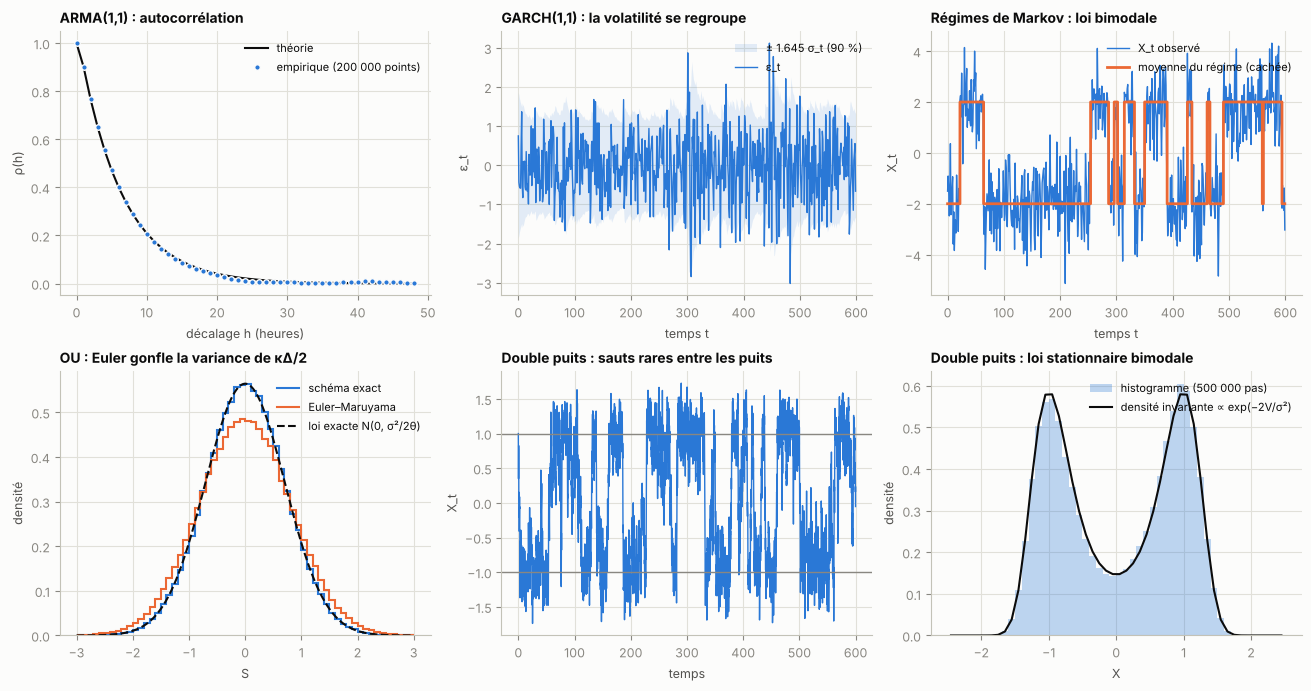

In [7]:
# Figure 1. One glance at each generator (the numbers are in the table above).
INK, INK2, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#fcfcfb"
# categorical slots 1-5
BLUE, ORANGE, AQUA, YELLOW, MAGENTA = (
    "#2a78d6",
    "#eb6834",
    "#1baf7a",
    "#eda100",
    "#e87ba4",
)
plt.rcParams.update(
    {
        "figure.facecolor": SURFACE,
        "axes.facecolor": SURFACE,
        "savefig.facecolor": SURFACE,
        "axes.edgecolor": "#c3c2b7",
        "axes.labelcolor": INK2,
        "text.color": INK,
        "xtick.color": MUTED,
        "ytick.color": MUTED,
        "axes.grid": True,
        "grid.color": GRID,
        "grid.linewidth": 0.8,
        "axes.axisbelow": True,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "lines.linewidth": 2,
        "font.size": 9,
        "axes.titlesize": 10,
        "axes.titleweight": "bold",
        "axes.titlelocation": "left",
        "legend.frameon": False,
        "legend.fontsize": 8,
        "figure.dpi": 100,
    }
)
rng = np.random.default_rng(SEED + 10)
fig, ax = plt.subplots(2, 3, figsize=(13, 6.8), constrained_layout=True)

# (a) ARMA(1,1): empirical autocorrelation against the closed form rho(h) = phi^(h-1) rho(1)
S, _ = sim_arma11(200_000, 0.85, 0.30, 1.0, rng)
lags = np.arange(0, 49)
emp = [np.corrcoef(S[: len(S) - k], S[k:])[0, 1] for k in lags]
rho1 = (1 + 0.85 * 0.30) * (0.85 + 0.30) / (1 + 2 * 0.85 * 0.30 + 0.30**2)
a = ax[0, 0]
a.plot(
    lags, np.r_[1.0, rho1 * 0.85 ** (lags[1:] - 1)], color=INK, lw=1.5, label="théorie"
)
a.plot(
    lags,
    emp,
    "o",
    color=BLUE,
    ms=4,
    mec=SURFACE,
    mew=1,
    label="empirique (200 000 points)",
)
a.set(title="ARMA(1,1) : autocorrélation", xlabel="décalage h (heures)", ylabel="ρ(h)")
a.legend(loc="upper right")

# (b) AR-GARCH innovations: the +/- z sigma_t band widens and narrows
_, e, s2 = sim_ar_garch(600, 0.0, 0.05, 0.10, 0.85, rng)
a, t = ax[0, 1], np.arange(600)
a.fill_between(
    t,
    -Z * np.sqrt(s2),
    Z * np.sqrt(s2),
    color=BLUE,
    alpha=0.12,
    lw=0,
    label="± 1.645 σ_t (90 %)",
)
a.plot(t, e, color=BLUE, lw=1, label="ε_t")
a.set(title="GARCH(1,1) : la volatilité se regroupe", xlabel="temps t", ylabel="ε_t")
a.legend(loc="upper right")

# (c) two hidden regimes: the observed series is a noisy view of a step function
xm_, sm_ = sim_markov_switching(600, P, mu_k, sd_k, rng)
a = ax[0, 2]
a.plot(t, xm_, color=BLUE, lw=1, label="X_t observé")
a.plot(
    t,
    np.asarray(mu_k)[sm_],
    color=ORANGE,
    lw=2,
    drawstyle="steps-post",
    label="moyenne du régime (cachée)",
)
a.set(title="Régimes de Markov : loi bimodale", xlabel="temps t", ylabel="X_t")
a.legend(loc="upper right")

# (d) Ornstein-Uhlenbeck sampled with dt = 0.5: exact scheme versus Euler-Maruyama (stationary laws)
a, grid_ = ax[1, 0], np.linspace(-3, 3, 400)
for scheme, col, lab in (
    ("exact", BLUE, "schéma exact"),
    ("euler", ORANGE, "Euler–Maruyama"),
):
    h_, edges_ = np.histogram(
        sim_ou(200_000, 1.0, 1.0, 0.5, rng, scheme),
        bins=60,
        range=(-3, 3),
        density=True,
    )
    a.stairs(h_, edges_, color=col, lw=1.5, label=lab)
a.plot(
    grid_,
    stats.norm.pdf(grid_, scale=np.sqrt(0.5)),
    color=INK,
    lw=1.5,
    ls="--",
    label="loi exacte N(0, σ²/2θ)",
)
a.set(title="OU : Euler gonfle la variance de κΔ/2", xlabel="S", ylabel="densité")
a.legend(loc="upper right")

# (e) double well: rare jumps between the two wells
a, tt = ax[1, 1], np.arange(60_000) * dt_w
a.plot(tt[::10], xw[:60_000:10], color=BLUE, lw=1)
for well in (-1, 1):
    a.axhline(well, color=MUTED, lw=1)
a.set(title="Double puits : sauts rares entre les puits", xlabel="temps", ylabel="X_t")

# (f) its occupation histogram against the invariant density exp(-2 V / sigma^2)
a = ax[1, 2]
a.stairs(
    hist, edges, fill=True, color=BLUE, alpha=0.30, label="histogramme (500 000 pas)"
)
a.plot(centres, dens, color=INK, lw=1.5, label="densité invariante ∝ exp(−2V/σ²)")
a.set(title="Double puits : loi stationnaire bimodale", xlabel="X", ylabel="densité")
a.legend(loc="upper right")
plt.show()

## 3. Méthodes usuelles et métriques

| Méthode | Principe | Équivalent (sklearn, R) | Première limite attendue |
|---|---|---|---|
| Persistance | $\hat X_{t+h}=X_t$ | R `forecast::naive` | biais saisonnier ; variance $2\gamma(0)(1-\rho(h))$ |
| Naïve saisonnière | $\hat X_{t+h}=X_{t+h-m\lceil h/m\rceil}$ ; échelle du MASE | R `forecast::snaive` | recopie une observation bruitée |
| Climatologie harmonique | $\hat\mu_t=\hat\beta^\top d(t)$ par moindres carrés | `LinearRegression` ; R `lm` | ignore l'anomalie courante ; extrapole la tendance |
| Climatologie + AR direct | anomalie à $t+h$ régressée sur les $p$ dernières, un modèle par $h$ | `LinearRegression` sur retards | $p$ fixé ; pas de loi |
| Intervalle gaussien | $\hat y\pm z\hat s$ | `scipy.stats.norm` | couverture conditionnelle non uniforme |
| Conforme séparé | $\hat y\pm\hat q$ ; $\hat q$ = statistique d'ordre $\lceil(n+1)(1-\alpha)\rceil$ des résidus absolus de calibration [LGRTW18] | `numpy` | garantie marginale, sous échangeabilité |
| Conforme glissant | même rang sur les $W$ derniers résidus | idem | garantie perdue ; compromis sur $W$ |
| Régression quantile + proxy de volatilité | quantiles linéaires en la moyenne des résidus absolus sur 24 h [KB78] | `QuantileRegressor` ; R `quantreg::rq` | dépend du proxy ; croisements |
| GARCH(1,1), quasi-vraisemblance | $\hat y\pm z\hat\sigma_t$ | `scipy.optimize` ; Python `arch` ; R `rugarch` | gaussien ; paramètres figés |

*Conforme séparé* : on ajuste le modèle, on calcule les erreurs absolues sur un bloc de calibration de $n$ points, on prend leur quantile d'ordre $\lceil(n+1)(1-\alpha)\rceil/n$ et l'intervalle est « prévision ± ce quantile ». *Glissant* : même recette, mais le quantile est recalculé à chaque instant sur les $W$ dernières erreurs déjà observées ([annexe P12 : exemple chiffré et preuve](https://github.com/GalaxiLir/stats-to-deeplearning/blob/main/01-ts-uncertainty/docs/00b_annexe_technique.md#P12)).

**Métriques.** MASE [HK06 ; HA18] : `tsunc.metrics.mase` ; pinball : `pinball_loss` ; couverture : `coverage` ; largeur moyenne : `mean_width`. Ces fonctions viennent du paquet et ne sont pas réécrites ; seule `interval_score` est ajoutée ici.

**Que mesure la « largeur moyenne de l'intervalle » ?** C'est $\frac1n\sum_i(u_i-l_i)$, dans l'unité de la série : la *finesse* (*sharpness*) de [GBR07], propriété des prévisions seules. Leur principe : maximiser la finesse *sous contrainte de calibration*. Un intervalle de largeur 0 est parfaitement fin et ne couvre presque jamais ; pour un oracle gaussien, la largeur à 90 % vaut $2z\sigma=3.29\,\sigma$ : c'est un plancher, pas un défaut. On lit donc la largeur avec la couverture, conditionnelle si possible.

**Calibration.** Une prévision est *calibrée* si les probabilités annoncées se réalisent : « 30 % de pluie » l'est si, les jours où il est annoncé, il pleut un jour sur trois ; pour un intervalle à 90 %, la valeur observée doit tomber dedans 90 % du temps. La calibration *marginale* est la moyenne sur tous les cas ; la *conditionnelle* est la même fréquence dans chaque groupe (ici, les terciles de volatilité de E2) ([annexe P13](https://github.com/GalaxiLir/stats-to-deeplearning/blob/main/01-ts-uncertainty/docs/00b_annexe_technique.md#P13)).

> **Idée 7 — le score d'intervalle est la perte pinball des deux bornes.** $\mathrm{IS}_\alpha=(u-l)+\tfrac2\alpha(l-y)_++\tfrac2\alpha(y-u)_+=\tfrac2\alpha\big[\rho_{\alpha/2}(y-l)+\rho_{1-\alpha/2}(y-u)\big]$, donc $\overline{\mathrm{IS}}=\tfrac4\alpha\,\overline{\text{pinball}}$. La condition du premier ordre $\partial_u\,\mathbb E[\mathrm{IS}]=1-\tfrac2\alpha\,\mathbb P(Y>u)=0$ donne $\mathbb P(Y>u)=\alpha/2$ : le score est propre et ne récompense pas la réduction de l'intervalle [GR07] (dans la version rapport technique lue, il est orienté à maximiser, $S=-2\alpha\,\mathrm{IS}_\alpha$ ; texte publié non relu). La cellule vérifie l'identité numériquement.

In [8]:
# The usual methods. Metrics come from tsunc.metrics (pinball_loss, mase, coverage, mean_width): not rewritten here.

# ---- point forecasts (E1): persistence, seasonal naive, climatology, climatology + AR on anomalies -------------
def fit_climatology(x, n_train, D):
    """OLS of x on the design over the TRAINING block only (sklearn; the design already has a constant)."""
    return LinearRegression(fit_intercept=False).fit(D[:n_train], x[:n_train]).coef_


def lag_matrix(a, p):
    """Rows t = p-1 .. len(a)-1; columns a_t, a_{t-1}, ..., a_{t-p+1}."""
    return np.column_stack([a[p - 1 - j : len(a) - j] for j in range(p)])


def direct_ar(anom, n_train, h, p=3):
    """Direct h-step AR(p): regress anom_{t+h} on (anom_t, ..., anom_{t-p+1}), training targets only.
    Returns the forecasts for the origins t = p-1 .. N-h-1 (entry r <-> origin t = r + p - 1)."""
    N = len(anom)
    X = lag_matrix(anom, p)[: N - h - (p - 1)]
    y = anom[h + p - 1 :]
    # origins whose target t+h is still inside the training block
    n_fit = n_train - h - (p - 1)
    return LinearRegression(fit_intercept=False).fit(X[:n_fit], y[:n_fit]).predict(X)


def point_forecasts(x, mu_hat, n_train, h, p=3):
    """Forecasts of x_{t+h} for the test origins t = n_train .. N-h-1, from information up to t only."""
    t0 = np.arange(n_train, len(x) - h)
    ar = direct_ar(x - mu_hat, n_train, h, p)
    preds = {
        "persistence": x[t0],
        # same hour of the latest day already observed
        "seasonal naive": x[t0 + h - M * int(np.ceil(h / M))],
        "climatology": mu_hat[t0 + h],
        "climatology + AR(3)": mu_hat[t0 + h] + ar[t0 - (p - 1)],
    }
    return preds, x[t0 + h]


def arma11_theory(phi, theta, sigma, h_max, m=M):
    """Oracle MASE and climatology MASE for ARMA(1,1) noise, from psi-weights (Gaussian errors: MAE ~ sqrt(2/pi) sd)."""
    # psi_0 .. psi_{h_max-1}
    psi = np.r_[1.0, (phi + theta) * phi ** np.arange(h_max - 1)]
    g0 = sigma**2 * (1 + 2 * phi * theta + theta**2) / (1 - phi**2)
    rho_m = (
        (1 + phi * theta)
        * (phi + theta)
        / (1 + 2 * phi * theta + theta**2)
        * phi ** (m - 1)
    )
    # E|S_{t+m} - S_t|: the MASE denominator
    scale = np.sqrt(2 / np.pi) * np.sqrt(2 * g0 * (1 - rho_m))
    oracle = np.sqrt(2 / np.pi) * np.sqrt(sigma**2 * np.cumsum(psi**2)) / scale
    clim = np.sqrt(2 / np.pi) * np.sqrt(g0) / scale
    return oracle, clim


# ---- one-step intervals (E2): same point forecast, different ways of building the interval ------------------------
def garch_filter(e, omega, alpha, beta, v0):
    """sigma^2_t = omega + alpha e_{t-1}^2 + beta sigma^2_{t-1}, vectorised with lfilter (e_{-1}^2 = sigma^2_{-1} = v0)."""
    x = omega + alpha * np.r_[v0, e[:-1] ** 2]
    return signal.lfilter([1.0], [1.0, -beta], x, zi=[beta * v0])[0]


def fit_garch11(e):
    """Gaussian quasi-maximum-likelihood fit of a GARCH(1,1) on the residuals e (scipy)."""
    v0 = e.var()

    def nll(par):
        s2 = garch_filter(e, *par, v0)
        return 0.5 * np.sum(np.log(s2) + e**2 / s2)

    res = optimize.minimize(
        nll,
        x0=[0.05 * v0, 0.1, 0.8],
        method="L-BFGS-B",
        bounds=[(1e-6, None), (1e-4, 0.5), (1e-4, 0.999)],
    )
    return res.x


def interval_score(y, lo, hi, alpha=ALPHA):
    """Mean interval score = (4/alpha) x pinball_loss at levels (alpha/2, 1 - alpha/2) = width + (2/alpha) x miss distance."""
    return (4 / alpha) * pinball_loss(
        y, np.stack([lo, hi], axis=-1), [alpha / 2, 1 - alpha / 2]
    )


def interval_methods(x, D, n_train, n_cal, w_vol=24, rolling=None, with_qr=True):
    """90 % one-step intervals for the targets k = n_train + n_cal .. N-1, from information up to k-1 only.
    Every method shares y_hat = mu_hat + AR(1) on the anomalies; they differ by the interval around it."""
    N = len(x)
    mu_hat = D @ fit_climatology(x, n_train, D)
    # entry r forecasts the anomaly at r + 1
    ar = direct_ar(x - mu_hat, n_train, 1, p=1)
    y_hat = np.r_[np.nan, mu_hat[1:] + ar]  # y_hat[k] forecasts x[k], k = 1 .. N-1
    resid = x - y_hat  # one-step residuals (NaN at k = 0)
    k_cal, k_te = np.arange(n_train, n_train + n_cal), np.arange(n_train + n_cal, N)
    out = {}
    # 1. Gaussian interval, constant variance estimated on the training residuals
    s = resid[1:n_train].std(ddof=1)
    out["Gaussian, constant variance"] = (y_hat[k_te] - Z * s, y_hat[k_te] + Z * s)
    # 2. split conformal: empirical quantile of the calibration residuals, rank ceil((n+1)(1-alpha))
    q = np.sort(np.abs(resid[k_cal]))[int(np.ceil((n_cal + 1) * (1 - ALPHA))) - 1]
    out["split conformal"] = (y_hat[k_te] - q, y_hat[k_te] + q)
    # 3. rolling conformal (optional): same rank, but on the `rolling` most recent residuals only
    if rolling:
        rank = int(np.ceil((rolling + 1) * (1 - ALPHA)))
        # row i: targets i+1 .. i+W
        win = np.lib.stride_tricks.sliding_window_view(np.abs(resid[1:]), rolling)
        # rank-th smallest of each window
        kth = np.partition(win, rank - 1, axis=1)[:, rank - 1]
        q_roll = kth[k_te - rolling - 1]  # window of targets k-W .. k-1
        out[f"rolling conformal (W={rolling})"] = (
            y_hat[k_te] - q_roll,
            y_hat[k_te] + q_roll,
        )
    # 4. linear quantile regression of the residual on a volatility proxy: mean |residual| over the last 24 h
    if with_qr:
        vol = pd.Series(np.abs(resid)).rolling(w_vol, min_periods=1).mean().to_numpy()
        # row j <-> target k = j + 1, feature known at k - 1
        F = vol[:-1].reshape(-1, 1)
        fit = np.arange(2, n_train)  # vol[0] is undefined (no residual at k = 0)
        bands = [
            y_hat[k_te]
            + QuantileRegressor(quantile=tau, alpha=0.0, solver="highs")
            .fit(F[fit - 1], resid[fit])
            .predict(F[k_te - 1])
            for tau in (ALPHA / 2, 1 - ALPHA / 2)
        ]
        out["quantile regression + volatility proxy"] = (
            np.minimum(*bands),
            np.maximum(*bands),
        )
    # 5. GARCH(1,1) by Gaussian quasi-likelihood, fitted on the training residuals, filtered causally afterwards
    e_tr = resid[1:n_train]
    omega, a, b = fit_garch11(e_tr)
    # entry j <-> target k = j + 1
    s2 = garch_filter(np.nan_to_num(resid[1:]), omega, a, b, e_tr.var())
    sd = np.sqrt(s2[k_te - 1])
    out["GARCH(1,1), quasi-likelihood"] = (y_hat[k_te] - Z * sd, y_hat[k_te] + Z * sd)
    return out


# ---- sanity check of the interval-score identity against its explicit formula -------------------------------------
_r = np.random.default_rng(0)
_y, _lo, _hi = (
    _r.normal(size=1_000),
    -_r.uniform(0.2, 1.5, 1_000),
    _r.uniform(0.2, 1.5, 1_000),
)
_explicit = np.mean(
    (_hi - _lo)
    + 2 / ALPHA * np.maximum(_lo - _y, 0)
    + 2 / ALPHA * np.maximum(_y - _hi, 0)
)
assert np.isclose(interval_score(_y, _lo, _hi), _explicit)
print(
    "interval score = (4/alpha) x pinball_loss: identity verified on random intervals"
)

interval score = (4/alpha) x pinball_loss: identity verified on random intervals


## 4. E1 — mémoire courte : ce que chaque couche apporte, selon l'horizon

Bruit ARMA(1,1) ($\varphi=0.85$, $\theta=0.30$), $h=1,\dots,24$, apprentissage 6000 h, test 1500 h, $R=20$ répliques. MASE avec l'échelle de la naïve saisonnière d'apprentissage.

**Prédictions théoriques.** Erreur quadratique de la persistance : $\Delta\mu_h^2+2\gamma(0)(1-\rho(h))$, où $\Delta\mu_h^2$ est la moyenne de $(\mu_{t+h}-\mu_t)^2$ ; celle de la climatologie : $\gamma(0)$. La persistance gagne si et seulement si $\rho(h)>\frac12+\Delta\mu_h^2/(2\gamma(0))$. MASE de la climatologie : $1/\sqrt{2(1-\rho(24))}=0.715$. MASE de l'oracle : $\sigma\sqrt{\sum_{j<h}\psi_j^2}\,/\sqrt{2\gamma(0)(1-\rho(24))}$ (courbe en tirets de la figure).

In [9]:
# E1. What does each layer add, and how does it fade with the horizon h?  Noise: ARMA(1,1), phi = 0.85, theta = 0.30.
HS = np.arange(1, 25)
N_TRAIN, N_TEST, R = 6000, 1500, 20
N1 = N_TRAIN + N_TEST
PHI, THETA, SIG = 0.85, 0.30, 1.0
D1, MU1 = design(N1), design(N1) @ BETA


def run_e1(rng):
    S, e = sim_arma11(N1, PHI, THETA, SIG, rng)
    x = MU1 + S
    # climatology fitted on the training block only
    mu_hat = D1 @ fit_climatology(x, N_TRAIN, D1)
    res = {}
    for h in HS:
        preds, y = point_forecasts(x, mu_hat, N_TRAIN, h)
        t0 = np.arange(N_TRAIN, N1 - h)
        # oracle: E[S_{t+h} | F_t] = phi^(h-1) (phi S_t + theta e_t), with the true parameters and the true state
        preds["oracle (true parameters)"] = MU1[t0 + h] + PHI ** (h - 1) * (
            PHI * S[t0] + THETA * e[t0]
        )
        for name, p in preds.items():
            res.setdefault(name, []).append(mase(y, p, y_train=x[:N_TRAIN], m=M))
    return {k: np.array(v) for k, v in res.items()}


runs = [run_e1(np.random.default_rng(s)) for s in np.random.SeedSequence(SEED).spawn(R)]
mase_mean = {k: np.mean([r[k] for r in runs], axis=0) for k in runs[0]}
mase_se = {
    k: np.std([r[k] for r in runs], axis=0, ddof=1) / np.sqrt(R) for k in runs[0]
}
th_oracle, th_clim = arma11_theory(PHI, THETA, SIG, HS.max())

table = pd.DataFrame(
    {k: v[[0, 5, 11, 23]] for k, v in mase_mean.items()},
    index=["h = 1", "h = 6", "h = 12", "h = 24"],
).T
table.loc["theory: oracle"] = th_oracle[[0, 5, 11, 23]]
table.loc["theory: climatology"] = th_clim
print(
    f"MASE (scale: seasonal naive on the training block), mean of {R} replicates; max s.e. = "
    f"{max(se.max() for se in mase_se.values()):.3f}"
)
gap = np.abs(
    mase_mean["climatology + AR(3)"] - mase_mean["oracle (true parameters)"]
).max()
print(f"largest gap |climatology + AR(3) - oracle| over h = 1..24: {gap:.3f}")
print(
    "persistence MASE at h = 1..4:",
    np.round(mase_mean["persistence"][:4], 3),
    "| climatology:",
    round(float(mase_mean["climatology"][0]), 3),
)
table

MASE (scale: seasonal naive on the training block), mean of 20 replicates; max s.e. = 0.018
largest gap |climatology + AR(3) - oracle| over h = 1..24: 0.004
persistence MASE at h = 1..4: [0.366 0.608 0.802 0.971] | climatology: 0.718


,h = 1,h = 6,h = 12,h = 24
persistence,0.366,1.251,1.628,0.999
seasonal naive,0.998,0.999,0.999,0.999
climatology,0.718,0.718,0.718,0.718
climatology + AR(3),0.296,0.656,0.711,0.718
oracle (true parameters),0.296,0.652,0.706,0.714
theory: oracle,0.298,0.654,0.707,0.715
theory: climatology,0.715,0.715,0.715,0.715


In [10]:
# Anti-leakage guard: forecasts issued at or before an origin must not change when the data AFTER it is scrambled.
rng = np.random.default_rng(1)
S, _ = sim_arma11(N1, PHI, THETA, SIG, rng)
x = MU1 + S
mu_hat = D1 @ fit_climatology(x, N_TRAIN, D1)
origin = N_TRAIN + 500
x_alt = x.copy()
x_alt[origin + 1 :] += 100 * rng.standard_normal(N1 - origin - 1)

for h in (1, 24):  # point forecasts
    a, _ = point_forecasts(x, mu_hat, N_TRAIN, h)
    b, _ = point_forecasts(x_alt, mu_hat, N_TRAIN, h)
    keep = np.arange(N_TRAIN, N1 - h) <= origin
    assert all(np.allclose(a[k][keep], b[k][keep]) for k in a), h

n_tr, n_cal = 5000, 1000  # intervals (all five methods)
a = interval_methods(x, D1, n_tr, n_cal, rolling=300)
b = interval_methods(x_alt, D1, n_tr, n_cal, rolling=300)
keep = np.arange(n_tr + n_cal, N1) <= origin
bad = [
    name
    for name in a
    if not all(np.allclose(u[keep], v[keep]) for u, v in zip(a[name], b[name]))
]
assert not bad, bad
print(
    "no leakage: forecasts at or before the origin are unchanged when the future is scrambled"
)

no leakage: forecasts at or before the origin are unchanged when the future is scrambled


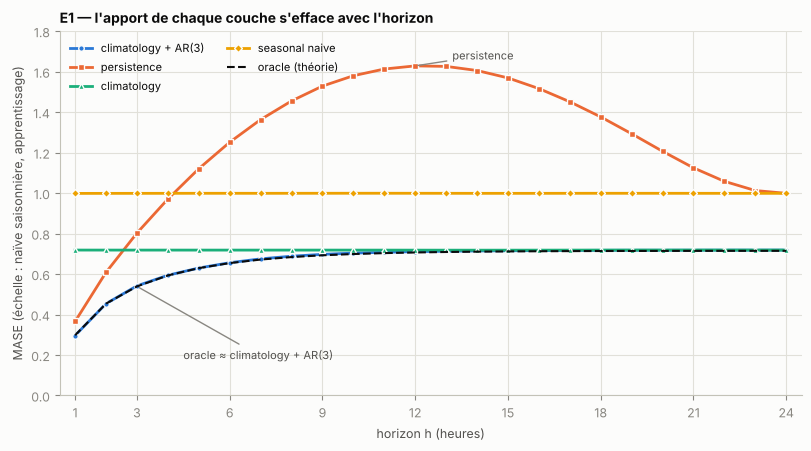

In [11]:
# Figure 2. E1: MASE against the horizon.  Persistence wins at h = 1 and loses beyond a few hours; every curve
# ends at the climatology (0.72) once the noise has forgotten the present; the oracle is the floor.
STYLE_E1 = {
    "climatology + AR(3)": (BLUE, "o"),
    "persistence": (ORANGE, "s"),
    "climatology": (AQUA, "^"),
    "seasonal naive": (YELLOW, "D"),
}
fig, a = plt.subplots(figsize=(8, 4.4), constrained_layout=True)
for name, (col, mk) in STYLE_E1.items():
    a.plot(
        HS, mase_mean[name], color=col, marker=mk, ms=4, mec=SURFACE, mew=1, label=name
    )
a.plot(HS, th_oracle, color=INK, lw=1.5, ls="--", label="oracle (théorie)")
a.annotate(
    "persistence",
    (12, mase_mean["persistence"][11]),
    xytext=(13.2, 1.66),
    color=INK2,
    fontsize=8,
    arrowprops={"arrowstyle": "-", "color": MUTED, "lw": 1},
)
a.annotate(
    "oracle ≈ climatology + AR(3)",
    (3, th_oracle[2]),
    xytext=(4.5, 0.18),
    color=INK2,
    fontsize=8,
    arrowprops={"arrowstyle": "-", "color": MUTED, "lw": 1},
)
a.set(
    title="E1 — l'apport de chaque couche s'efface avec l'horizon",
    xlabel="horizon h (heures)",
    ylabel="MASE (échelle : naïve saisonnière, apprentissage)",
    ylim=(0, 1.8),
    xlim=(0.5, 24.5),
)
a.set_xticks([1, 3, 6, 9, 12, 15, 18, 21, 24])
a.legend(loc="upper left", ncol=2)
plt.show()

**Lecture.** La persistance bat la climatologie à $h=1,2$ (0.37 et 0.61 contre 0.72) et la perd dès $h=3$ : $\rho(h)$ passe sous le seuil entre $h=2$ et $h=3$, comme le prédit le critère. Elle culmine à 1.63 vers $h=12$, où le cycle quotidien est en opposition de phase et $\Delta\mu_h$ domine. La naïve saisonnière vaut 1 par construction (c'est l'échelle). « Climatologie + AR(3) » colle à l'oracle (écart maximal imprimé plus haut) : la partie MA est inversible avec $|\theta|=0.3$ et ses poids AR décroissent comme $0.3^j$. Toutes les courbes rejoignent la climatologie (théorie 0.715, simulation 0.718) quand la mémoire est épuisée.

*Ne prouve pas* : la hiérarchie sur des données réelles ; un seul jeu de paramètres ; les écarts de l'ordre de 0.01 sont dans le bruit ($R=20$).

## 5. E2 — intervalles quand la variance bouge

Même modèle de moyenne pour toutes les méthodes (climatologie + AR(1) sur les anomalies, un pas) ; seul l'intervalle change. Bruit : AR(0.7) à innovations GARCH(0.05, 0.10, 0.85) ; blocs de 6000 h (apprentissage), 1500 h (calibration) et 1500 h (test) ; $R=20$. Les colonnes `cov. | … vol.` sont les couvertures par tercile de la **vraie** $\sigma_t$ (connue en simulation) : la couverture *conditionnelle*, que la couverture marginale cache (Idée 3).

In [12]:
# E2. Same mean model, different intervals. Noise: AR(1) driven by GARCH(1,1) innovations (volatility clusters).
# sigma_bar^2 = 1 ; volatility persistence alpha + beta = 0.95
PHI2, G_OMEGA, G_A, G_B = (0.7, 0.05, 0.10, 0.85)
N_TR, N_CAL, N_TE, R2 = 6000, 1500, 1500, 20
N2 = N_TR + N_CAL + N_TE
D2 = design(N2)
MU2 = D2 @ BETA
TERCILES = ["low", "mid", "high"]


def run_e2(rng, break_factor=None, rolling=None, with_qr=True):
    """One replicate. Returns the test targets, the intervals of every method and the true conditional sd."""
    scale = (
        None
        if break_factor is None
        else np.r_[np.ones(N_TR + N_CAL), break_factor * np.ones(N_TE)]
    )
    S, _, s2 = sim_ar_garch(N2, PHI2, G_OMEGA, G_A, G_B, rng, scale=scale)
    x = MU2 + S
    out = interval_methods(x, D2, N_TR, N_CAL, rolling=rolling, with_qr=with_qr)
    k = np.arange(N_TR + N_CAL, N2)
    # oracle: true sigma_t and true state S_{t-1}
    sd, centre = (np.sqrt(s2[k]), MU2[k] + PHI2 * S[k - 1])
    out["oracle (true sigma_t)"] = (centre - Z * sd, centre + Z * sd)
    return x[k], out, sd


def summarize(y, out, sd):
    """Coverage overall and by tercile of the TRUE conditional sd, mean width, interval score."""
    terc = np.digitize(sd, np.quantile(sd, [1 / 3, 2 / 3]))
    rows = {}
    for name, (lo, hi) in out.items():
        rows[name] = {
            "coverage": coverage(y, lo, hi),
            **{
                f"cov. | {lab} vol.": coverage(
                    y[terc == i], lo[terc == i], hi[terc == i]
                )
                for i, lab in enumerate(TERCILES)
            },
            "mean width": mean_width(lo, hi),
            "interval score": interval_score(y, lo, hi),
        }
    return pd.DataFrame(rows).T


tables = [
    summarize(*run_e2(np.random.default_rng(s)))
    for s in np.random.SeedSequence([SEED, 2]).spawn(R2)
]
e2 = sum(tables) / R2
print(
    f"One-step 90 % intervals, mean of {R2} replicates (test block of {N_TE} hours each)."
)
e2

One-step 90 % intervals, mean of 20 replicates (test block of 1500 hours each).


,coverage,cov. | low vol.,cov. | mid vol.,cov. | high vol.,mean width,interval score
"Gaussian, constant variance",0.903,0.964,0.921,0.823,3.269,4.267
split conformal,0.904,0.965,0.922,0.826,3.298,4.276
quantile regression + volatility proxy,0.902,0.920,0.907,0.878,3.205,4.079
"GARCH(1,1), quasi-likelihood",0.901,0.903,0.902,0.898,3.202,4.003
oracle (true sigma_t),0.901,0.902,0.901,0.900,3.205,3.997


**Lecture E2.** Tous les intervalles couvrent 0.90 en moyenne. L'intervalle gaussien à variance constante et le conforme séparé couvrent pourtant 0.96 quand la volatilité est faible et 0.82 quand elle est forte : la bonne moyenne de couvertures conditionnelles inégales (Idée 3). La régression quantile avec proxy corrige en partie (0.92, 0.91, 0.88) ; GARCH et oracle presque entièrement (0.90 partout). Les largeurs moyennes (3.27 et 3.30 contre 3.20) séparent à peine ces méthodes ; le score d'intervalle (4.27 contre 4.00) les sépare. *Ne prouve pas* un classement : le vrai modèle est un GARCH gaussien, ce qui favorise GARCH par construction ; un pas seulement.

### E2b — une rupture que la calibration ne peut pas connaître

L'écart-type des innovations est multiplié par 2 (variance × 4) juste après la calibration. Le conforme garantit une couverture sous échangeabilité ; ici elle est fausse.

In [13]:
# E2b. The variance doubles right after the calibration block: a break the calibration cannot know about.
W = 500
KEEP = [
    "Gaussian, constant variance",
    "split conformal",
    f"rolling conformal (W={W})",
    "GARCH(1,1), quasi-likelihood",
]


def run_break(rng):
    y, out, sd = run_e2(rng, break_factor=2.0, rolling=W, with_qr=False)
    # 1 if the interval covers y_t
    hits_ = {k: ((y >= out[k][0]) & (y <= out[k][1])).astype(float) for k in KEEP}
    lo, hi = out["GARCH(1,1), quasi-likelihood"]
    late = slice(750, N_TE)  # long after the break
    return hits_, np.mean(((hi - lo)[late] / (2 * Z)) ** 2), np.mean(sd[late] ** 2)


runs_b = [
    run_break(np.random.default_rng(s))
    for s in np.random.SeedSequence([SEED, 3]).spawn(R2)
]
# coverage at each test step (over replicates)
hit = {k: np.mean([r[0][k] for r in runs_b], axis=0) for k in KEEP}
windows = {
    "first 250 h": slice(0, 250),
    "250-750 h": slice(250, 750),
    "750-1500 h": slice(750, N_TE),
    "whole block": slice(0, N_TE),
}
after_break = pd.DataFrame(
    {k: {w: v[s].mean() for w, s in windows.items()} for k, v in hit.items()}
).T
print(
    "Coverage of the 90 % intervals after a x2 jump of the innovation sd (nominal 0.90):"
)
print(
    f"last 750 h: variance used by GARCH = {np.mean([r[1] for r in runs_b]):.3f}, true conditional variance = "
    f"{np.mean([r[2] for r in runs_b]):.3f}, fixed point (omega + 4 a)/(1 - b) = {(G_OMEGA + 4 * G_A) / (1 - G_B):.3f}"
)
after_break

Coverage of the 90 % intervals after a x2 jump of the innovation sd (nominal 0.90):
last 750 h: variance used by GARCH = 2.995, true conditional variance = 4.026, fixed point (omega + 4 a)/(1 - b) = 3.000


,first 250 h,250-750 h,750-1500 h,whole block
"Gaussian, constant variance",0.577,0.625,0.608,0.608
split conformal,0.569,0.618,0.599,0.600
rolling conformal (W=500),0.699,0.909,0.890,0.865
"GARCH(1,1), quasi-likelihood",0.812,0.834,0.826,0.826


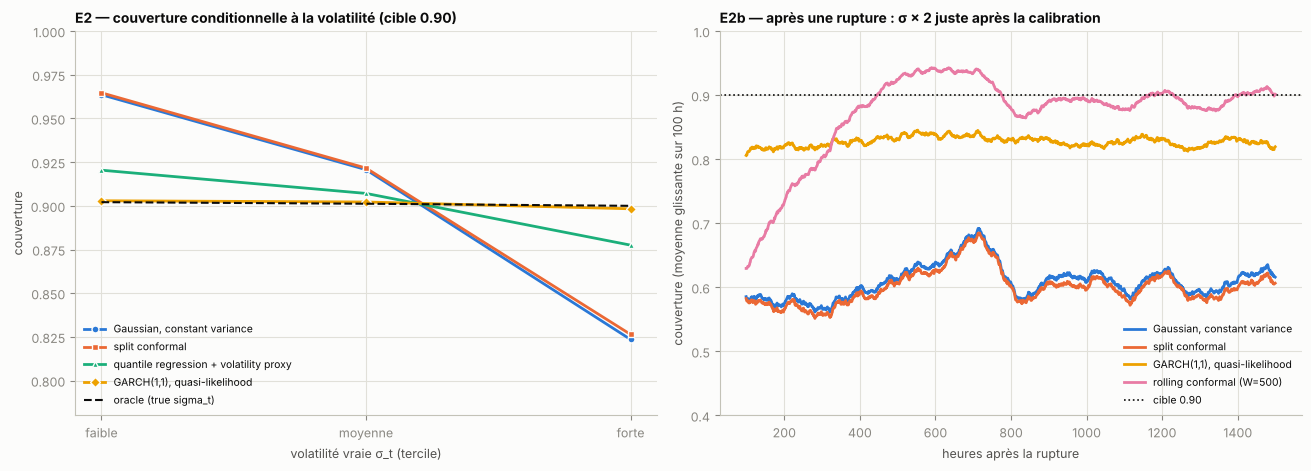

In [14]:
# Figure 3. E2 (left): coverage by volatility level, all methods near 0.90 on average.  E2b (right): after a variance break.
STYLE_E2 = {
    "Gaussian, constant variance": (BLUE, "o"),
    "split conformal": (ORANGE, "s"),
    "quantile regression + volatility proxy": (AQUA, "^"),
    "GARCH(1,1), quasi-likelihood": (YELLOW, "D"),
    f"rolling conformal (W={W})": (MAGENTA, "v"),
}
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4.6), constrained_layout=True)

cols = ["cov. | low vol.", "cov. | mid vol.", "cov. | high vol."]
for name, (col, mk) in STYLE_E2.items():
    if name in e2.index:
        a1.plot(
            range(3),
            e2.loc[name, cols],
            color=col,
            marker=mk,
            ms=5,
            mec=SURFACE,
            mew=1,
            label=name,
        )
a1.plot(
    range(3),
    e2.loc["oracle (true sigma_t)", cols],
    color=INK,
    lw=1.5,
    ls="--",
    label="oracle (true sigma_t)",
)
a1.set_xticks(range(3), ["faible", "moyenne", "forte"])
a1.set(
    title="E2 — couverture conditionnelle à la volatilité (cible 0.90)",
    xlabel="volatilité vraie σ_t (tercile)",
    ylabel="couverture",
    ylim=(0.78, 1.0),
)
a1.legend(loc="lower left", fontsize=7.5)

for name, (col, mk) in STYLE_E2.items():
    if name in hit:
        a2.plot(
            np.arange(N_TE),
            pd.Series(hit[name]).rolling(100).mean(),
            color=col,
            lw=2,
            label=name,
        )
a2.axhline(1 - ALPHA, color=INK, lw=1.2, ls=":", label="cible 0.90")
a2.set(
    title="E2b — après une rupture : σ × 2 juste après la calibration",
    xlabel="heures après la rupture",
    ylabel="couverture (moyenne glissante sur 100 h)",
    ylim=(0.4, 1.0),
)
a2.legend(loc="lower right", fontsize=7.5)
plt.show()

**Lecture E2b.** Les méthodes figées (gaussien, conforme séparé) tombent à environ 0.60. Le conforme glissant ($W=500$) ne réagit pas plus vite que sa fenêtre (0.70 sur les 250 premières heures) puis revient à 0.91. GARCH s'adapte mais reste à 0.83 : sa variance est rappelée vers l'ancien niveau $\bar\sigma^2=1$, et le point fixe après la rupture est $(\omega+4a)/(1-b)=3$ au lieu de 4 (variance utilisée et variance vraie imprimées plus haut) ; avec un écart-type uniformément sous-estimé d'un facteur $\sqrt{3/4}$, la couverture gaussienne serait 0.846. *Ne prouve pas* : un seul facteur de rupture (× 2) et une seule date.

### E2c — une loi prédictive qui n'est pas gaussienne

Deux régimes de Markov (Idée 4), une trajectoire de 60 000 points, première moitié pour l'apprentissage. Le concurrent est l'intervalle gaussien d'une régression directe AR(1) ; l'oracle connaît le régime courant (information supérieure à $\mathcal F_t$, voir les limites) et prend les quantiles du mélange.

In [15]:
# E2c. A non-Gaussian predictive law: two hidden regimes (a weather-generator-like chain), see Idea 4.
# The oracle knows the hidden regime; the competitor is the Gaussian direct-AR interval fitted on the first half.
P_M, MU_M, SD_M = (
    np.array([[0.95, 0.05], [0.05, 0.95]]),
    np.array([-2.0, 2.0]),
    np.array([1.0, 1.0]),
)
xm, sm = sim_markov_switching(60_000, P_M, MU_M, SD_M, np.random.default_rng(SEED + 7))
n_fit = len(xm) // 2


def mixture_interval(state, h, alpha):
    """Equal-tailed interval of X_{t+h} | s_t = state: quantiles of sum_k (P^h)[state, k] N(mu_k, sd_k^2)."""
    w = np.linalg.matrix_power(P_M, h)[state]
    cdf = lambda v, p: w @ stats.norm.cdf((v - MU_M) / SD_M) - p
    return [
        optimize.brentq(cdf, -15, 15, args=(p,)) for p in (alpha / 2, 1 - alpha / 2)
    ]


rows = []
for h in (1, 24):
    # direct AR(1): x_{t+h} on x_t
    A = np.column_stack([np.ones(n_fit - h), xm[: n_fit - h]])
    b = np.linalg.lstsq(A, xm[h:n_fit], rcond=None)[0]
    s_h = (xm[h:n_fit] - A @ b).std(ddof=2)
    t0 = np.arange(n_fit, len(xm) - h)
    y, centre = xm[t0 + h], b[0] + b[1] * xm[t0]
    for alpha in (0.5, 0.1):
        z = stats.norm.ppf(1 - alpha / 2)
        lo_g, hi_g = centre - z * s_h, centre + z * s_h
        edges = {s: mixture_interval(s, h, alpha) for s in (0, 1)}
        lo_o, hi_o = (np.array([edges[s][i] for s in sm[t0]]) for i in (0, 1))
        for name, (lo, hi) in {
            "Gaussian AR": (lo_g, hi_g),
            "oracle (knows the regime)": (lo_o, hi_o),
        }.items():
            rows.append(
                {
                    "h": h,
                    "nominal": 1 - alpha,
                    "method": name,
                    "coverage": coverage(y, lo, hi),
                    "mean width": mean_width(lo, hi),
                }
            )
pd.DataFrame(rows).set_index(["h", "nominal", "method"])

coverage  mean width
h  nominal method                                         
1  0.5     Gaussian AR                   0.533       2.079
           oracle (knows the regime)     0.504       1.438
   0.9     Gaussian AR                   0.905       5.070
           oracle (knows the regime)     0.900       4.239
24 0.5     Gaussian AR                   0.316       3.006
           oracle (knows the regime)     0.505       3.984
   0.9     Gaussian AR                   0.953       7.331
           oracle (knows the regime)     0.903       6.558

**Lecture E2c.** À $h=1$, l'intervalle gaussien est correct à 90 % (0.905) mais trop large (5.07 contre 4.24). À $h=24$, la loi prédictive est presque la loi marginale bimodale (poids $(P^{24})_{ik}\approx0.54$ et $0.46$) : l'intervalle gaussien à 90 % surcouvre (0.953, largeur 7.33 contre 6.56) et celui à 50 % ne couvre que 0.316, car il est centré dans la vallée entre les deux modes : la loi prédictive est mal représentée par une gaussienne. Vérification : $N(0,5)$ donne $\pm1.508$ et $\pm3.678$ (largeurs 3.016 et 7.356), de couvertures 0.311 et 0.953 sous le mélange, contre 0.316 (largeur 3.006) et 0.953 (7.331) observés. Calibré à un niveau, faux à un autre. *Ne prouve pas* : ce qu'apporterait un filtre de Hamilton (non implémenté).

## 6. E3 — tendance déterministe ou aléa ?

Deux modèles : **(D)** $X_t=a+b\,t/n+S_t$, avec $S$ stationnaire ; **(R)** $X_t=X_{t-1}+b/n+\varepsilon_t$, marche aléatoire avec dérive. Les deux « montent ». À $n$ fini, deux lois gaussiennes non dégénérées sont mutuellement absolument continues : aucun test n'a une puissance égale à 1 ; la séparation n'est qu'asymptotique.

> **Idée 8 — la variance de long terme, pas la variance.** Sous (D) avec $b=0$ et un régresseur lent, $\operatorname{Var}(\hat b)\approx 2\pi f_S(0)\big/\sum_tu_t^2$, où $u$ est le temps centré et $2\pi f_S(0)=\sum_h\gamma(h)$ (preuve par convergence dominée : [annexe T4](https://github.com/GalaxiLir/stats-to-deeplearning/blob/main/01-ts-uncertainty/docs/00b_annexe_technique.md#T4)). Or l'écart-type « iid » estime $\gamma(0)/\sum_tu_t^2$. Le rapport vaut $r=\sum_h\rho(h)=(1+\varphi)/(1-\varphi)$ pour un AR(1) : 3, 19 et 99 pour $\varphi=0.5,\,0.9,\,0.98$. La statistique $t$ est approximativement $N(0,r)$ ; le test à 5 % rejette donc avec la probabilité $2\{1-\Phi(1.96/\sqrt r)\}$ : 0.258, 0.653, 0.844. **Newey–West** [NW87] (estimateur *HAC* : robuste à l'hétéroscédasticité et à l'autocorrélation) estime $2\pi f_S(0)$ avec des poids de Bartlett ; il corrige l'écart-type de $\hat b$ sans modéliser la dépendance ni améliorer la prévision ([annexe P11](https://github.com/GalaxiLir/stats-to-deeplearning/blob/main/01-ts-uncertainty/docs/00b_annexe_technique.md#P11)). Il est asymptotique : [KV05] (résumé lu) rapportent des distorsions de taille qui croissent avec la corrélation sérielle.

**E3-A.** Taux de rejet de « pente nulle » (5 %) alors que la pente est nulle, selon $\varphi$ ; $\varphi=1$ est la marche aléatoire (régression fallacieuse [GN74] ; la question tendance ou aléa en macroéconomie : [NP82] ; suite en E3-D).

In [16]:
# E3-A. A "trend" that is only noise: how often does a slope test reject?  (n = 500, 2000 replicates, 5 % level)
def ar_matrix(phi, n, R, rng, burn=300):
    """R independent AR(1) paths as columns; phi = 1 gives a random walk (no stationary regime)."""
    z = rng.standard_normal((n + burn, R))
    if phi >= 1:
        return np.cumsum(z[burn:], axis=0)
    return signal.lfilter([1.0], [1.0, -phi], z, axis=0)[burn:]


def trend_t_stats(Y, lags):
    """t-statistic of the slope of each column of Y (n x R) regressed on [1, u], u = t/n:
    with i.i.d. standard errors, and with Newey-West (Bartlett kernel) standard errors."""
    n = Y.shape[0]
    uc = np.arange(n) / n - (n - 1) / (2 * n)  # centred regressor
    Suu = (uc**2).sum()
    Yc = Y - Y.mean(axis=0)
    b = uc @ Yc / Suu
    e = Yc - np.outer(uc, b)
    se_iid = np.sqrt((e**2).sum(axis=0) / (n - 2) / Suu)
    score = uc[:, None] * e  # score of the slope
    lrv = (score**2).sum(axis=0)  # long-run variance of the score, Bartlett weights
    for j in range(1, lags + 1):
        lrv += 2 * (1 - j / (lags + 1)) * (score[j:] * score[:-j]).sum(axis=0)
    return b / se_iid, b / (np.sqrt(lrv) / Suu)


n_obs, R3, L = 500, 2000, 22  # L = floor(sqrt(n)) lags for Newey-West
rng = np.random.default_rng(SEED + 3)
Y1 = ar_matrix(0.9, n_obs, 1, rng)  # cross-check against statsmodels' HAC
_, t_hac = trend_t_stats(Y1, L)
ref = OLS(Y1[:, 0], np.column_stack([np.ones(n_obs), np.arange(n_obs) / n_obs])).fit(
    cov_type="HAC", cov_kwds={"maxlags": L}
)
assert np.isclose(ref.tvalues[1], t_hac[0]), (ref.tvalues[1], t_hac[0])

rows = {}
for phi in (0.0, 0.5, 0.9, 0.98, 1.0):
    t_iid, t_nw = trend_t_stats(ar_matrix(phi, n_obs, R3, rng), L)
    # long-run variance / variance, AR(1)
    infl = (1 + phi) / (1 - phi) if phi < 1 else np.inf
    rows[phi] = {
        "theory, iid s.e. (asymptotic)": 2 * (1 - stats.norm.cdf(1.96 / np.sqrt(infl))),
        "rejections, iid s.e.": np.mean(np.abs(t_iid) > 1.96),
        "rejections, Newey-West s.e.": np.mean(np.abs(t_nw) > 1.96),
    }
print(
    "Share of replicates where the slope is 'significant' at 5 %, whereas the true slope is zero:"
)
display_table = pd.DataFrame(rows).T.rename_axis("phi (1 = random walk)")
rw = {
    n: np.mean(
        np.abs(trend_t_stats(ar_matrix(1.0, n, 1000, rng), int(n**0.5))[0]) > 1.96
    )
    for n in (100, 500, 2000)
}
print(
    "random walk, iid s.e., by sample size n:",
    {k: round(float(v), 3) for k, v in rw.items()},
)
display_table

Share of replicates where the slope is 'significant' at 5 %, whereas the true slope is zero:


random walk, iid s.e., by sample size n: {100: 0.866, 500: 0.949, 2000: 0.97}


,"theory, iid s.e. (asymptotic)","rejections, iid s.e.","rejections, Newey-West s.e."
phi (1 = random walk),,,
0.00,0.050,0.045,0.081
0.50,0.258,0.244,0.084
0.90,0.653,0.646,0.177
0.98,0.844,0.848,0.461
1.00,1.000,0.947,0.767


**Lecture E3-A.** Le test « iid » suit la théorie (0.244, 0.646, 0.848 contre 0.258, 0.653, 0.844) : il rejette « pas de tendance » dans 25 à 85 % des cas sur du bruit pur. Newey–West ramène ces taux à 8, 18 et 46 % : mieux, mais encore libéral (8.1 % même à $\varphi=0$) et peu efficace près de la racine unitaire, car la fenêtre $L=22$ est inférieure à la longueur de corrélation $1/(1-\varphi)=50$. Pour la marche aléatoire, le rejet « iid » vaut 0.866, 0.949 et 0.970 à $n=100,\,500,\,2000$. Pour $\varphi=1$, le taux de rejet tend vers 1 quand $n$ croît : voir E3-D, qui en donne la raison.

**E3-D — régression fallacieuse : l'asymptotique.** Si $S$ est une marche aléatoire, la pente $\hat b$ (en unités de $u=t/n$) est de l'ordre de $\sqrt n$ alors que son écart-type « iid » reste de l'ordre de 1 : $t_n/\sqrt n$ converge en loi vers une variable non dégénérée, donc $|t_n|\to\infty$ à la vitesse $\sqrt n$ ; la statistique de Durbin–Watson tend vers 0 comme $1/n$ ; $\operatorname{Var}(\hat b/\sqrt n)\to\frac65\sigma^2$ (principe d'invariance de Donsker et application continue : [annexe T5](https://github.com/GalaxiLir/stats-to-deeplearning/blob/main/01-ts-uncertainty/docs/00b_annexe_technique.md#T5)). C'est la limite $\varphi\to1$ de l'Idée 8. Historique : simulations de [GN74], cycles apparents de [NK81], asymptotique de [Phi86], cointégration de [EG87]. La cellule calcule, sur 1000 marches par taille $n$, le taux de rejet à 5 %, la médiane de $|t|/\sqrt n$, celle de $n\times\mathrm{DW}$ et $\operatorname{Var}(\hat b/\sqrt n)$ (théorie : 1.2).

In [17]:
# E3-D. Spurious regression, asymptotics: when S is a random walk, the "iid" t statistic of the slope
#       grows like sqrt(n).
rng = np.random.default_rng(SEED + 4)
rows = {}
for n in (100, 400, 1600, 6400):
    Y = ar_matrix(1.0, n, 1000, rng)  # 1000 random walks, innovation variance 1
    t_iid, _ = trend_t_stats(Y, 0)  # lags = 0: plain i.i.d. standard error
    uc = np.arange(n) / n - (n - 1) / (2 * n)  # centred regressor: the slope is per unit of u = t/n
    Yc = Y - Y.mean(axis=0)
    b = uc @ Yc / (uc**2).sum()
    e = Yc - np.outer(uc, b)
    dw = (np.diff(e, axis=0) ** 2).sum(axis=0) / (e**2).sum(axis=0)  # Durbin-Watson statistic of the residuals
    rows[n] = {
        "median |t| / sqrt(n)": np.median(np.abs(t_iid)) / np.sqrt(n),
        "P(|t| > 1.96)": np.mean(np.abs(t_iid) > 1.96),
        "median n x DW": np.median(n * dw),
        "Var(b / sqrt(n))  (theory 6/5)": np.var(b / np.sqrt(n)),
    }
pd.DataFrame(rows).T.rename_axis("n")

,median |t| / sqrt(n),P(|t| > 1.96),median n x DW,Var(b / sqrt(n)) (theory 6/5)
n,,,,
100,0.810,0.871,17.902,1.158
400,0.864,0.935,18.637,1.235
1600,0.931,0.974,17.593,1.278
6400,0.880,0.990,18.660,1.244


**Lecture E3-D.** Le taux de rejet tend vers 1 (0.87 à 0.99 de $n=100$ à $6400$) ; $|t|/\sqrt n$ et $n\times\mathrm{DW}$ se stabilisent (environ 0.8 à 0.9 et 18) ; $\operatorname{Var}(\hat b/\sqrt n)$ reste proche de 1.2 (1.16 à 1.28 ; erreur-type d'environ 0.05). *Prouve* : l'énoncé pour une régression sur le temps. *Ne prouve pas* : le cas de deux marches indépendantes (mêmes fonctionnelles browniennes, non calculé ici).

**E3-B — tests de racine unitaire, aux hypothèses nulles opposées.** Ce sont des *diagnostics* : ils ne pallient pas la dépendance AR, ils disent s'il faut différencier. ADF (Dickey–Fuller augmenté [SD84] ; loi limite : [DF79]) : $H_0$ = racine unitaire ; KPSS [KPSS92] : $H_0$ = stationnarité autour d'une tendance ([annexe P10 : lecture croisée et limites](https://github.com/GalaxiLir/stats-to-deeplearning/blob/main/01-ts-uncertainty/docs/00b_annexe_technique.md#P10)). Une rupture déterministe non modélisée est lue comme une composante aléatoire [Per89].

In [18]:
# E3-B. Unit-root tests. ADF: H0 = unit root.  KPSS: H0 = stationary around a linear trend.  (n = 500, 150 replicates)
def make_series(kind, n, rng, burn=200):
    t, z = np.arange(n), rng.standard_normal(n + burn)
    ar = lambda phi: signal.lfilter([1.0], [1.0, -phi], z)[burn:]
    if kind == "trend + AR(0.7)":
        return 0.02 * t + ar(0.7)
    if kind == "trend + AR(0.98)":
        return 0.02 * t + ar(0.98)
    if kind == "trend + level break, AR(0.7)":
        return 0.02 * t + 8.0 * (t >= n // 2) + ar(0.7)
    return np.cumsum(0.02 + z[burn:])  # random walk with drift


def unit_root_tests(x):
    # rejects "unit root"
    adf_rejects = adfuller(x, regression="ct", autolag="AIC")[1] < 0.05
    stat, _, _, crit = kpss(x, regression="ct", nlags="auto")
    return adf_rejects, stat > crit["5%"]  # rejects "stationary around a trend"


KINDS = [
    "trend + AR(0.7)",
    "random walk + drift",
    "trend + AR(0.98)",
    "trend + level break, AR(0.7)",
]
rng, res = np.random.default_rng(SEED + 4), {}
with warnings.catch_warnings():
    warnings.simplefilter("ignore")  # KPSS p-values are interpolated from a table
    for kind in KINDS:
        r = np.array([unit_root_tests(make_series(kind, 500, rng)) for _ in range(150)])
        res[kind] = {
            "ADF rejects unit root": r[:, 0].mean(),
            "KPSS rejects stationarity": r[:, 1].mean(),
        }
print("Share of replicates where each test rejects its null (5 %):")
pd.DataFrame(res).T

Share of replicates where each test rejects its null (5 %):


,ADF rejects unit root,KPSS rejects stationarity
trend + AR(0.7),1.000,0.087
random walk + drift,0.047,0.953
trend + AR(0.98),0.220,0.847
"trend + level break, AR(0.7)",0.507,1.000


**Lecture E3-B.** Les deux tests sont corrects aux extrêmes (tendance + AR(0.7) : ADF rejette dans 100 % des cas, KPSS dans 9 % ; marche aléatoire : ADF 5 %, KPSS 95 %). Dans la zone grise (tendance + AR(0.98)) ils se trompent dans le même sens : ADF ne rejette la racine unitaire que dans 22 % des cas, KPSS rejette la stationnarité dans 85 %. Une rupture de niveau fait rejeter KPSS dans 100 % des cas. *Ne prouve pas* : aucun réglage des retards ni de la fenêtre n'a été exploré ; avec 150 répliques, une fréquence voisine de 0.5 n'est connue qu'à ± 0.08 (deux erreurs-types).

> **Idée 9 — borné ou croissant.** Sous (D), la variance de l'erreur de prévision est bornée par $\gamma(0)$, plus l'erreur d'estimation de la droite, $\approx\frac{2\pi f_S(0)}{n}\big[1+12(\tfrac12+\tfrac hn)^2\big]$. Sous (R), elle vaut $h\sigma^2$ et croît sans borne. Les deux modèles donnent les mêmes intervalles tant que $h\ll1/(1-\varphi)$ et se séparent au-delà : se tromper ne coûte rien à court terme.

**E3-C.** Deux recettes (tendance + AR(1) ; marche aléatoire avec dérive) contre deux vérités, aux horizons 1, 24 et 100 ($n=500$ observations, 1000 répliques par vérité). La *couverture* à l'horizon $h$ est la fréquence avec laquelle la valeur observée à $t+h$ tombe dans l'intervalle à 90 % ; la *largeur* est la largeur moyenne de l'intervalle.

In [19]:
# E3-C. What the confusion costs when forecasting: two recipes, two truths, horizons 1, 24 and 100 (n = 500 observed).
def recipe_ts(x, hs):
    """Deterministic linear trend + AR(1) on the detrended series; Gaussian 90 % interval."""
    n, t = len(x), np.arange(len(x))
    coef = np.polyfit(t, x, 1)
    r = x - np.polyval(coef, t)
    phi = min(r[1:] @ r[:-1] / (r[:-1] @ r[:-1]), 0.999)
    s2 = np.var(r[1:] - phi * r[:-1], ddof=2)
    mid = np.polyval(coef, n - 1 + hs) + phi**hs * r[-1]
    sd = np.sqrt(s2 * (1 - phi ** (2 * hs)) / (1 - phi**2))  # bounded as h grows
    return mid - Z * sd, mid + Z * sd


def recipe_ds(x, hs):
    """Random walk with drift (difference once): the error variance grows linearly with h."""
    d = np.diff(x)
    mid, sd = x[-1] + hs * d.mean(), np.sqrt(hs * d.var(ddof=1))
    return mid - Z * sd, mid + Z * sd


hs, n_fit, rng, rows = np.array([1, 24, 100]), 500, np.random.default_rng(SEED + 5), []
for truth in ("trend + AR(0.7)", "random walk + drift"):
    sims = [make_series(truth, n_fit + 100, rng) for _ in range(1000)]
    # realised values at horizons 1, 24, 100
    y = np.array([s[n_fit - 1 + hs] for s in sims])
    for name, recipe in (
        ("trend + AR(1)", recipe_ts),
        ("random walk + drift", recipe_ds),
    ):
        lo, hi = (np.array(a) for a in zip(*[recipe(s[:n_fit], hs) for s in sims]))
        for j, h in enumerate(hs):
            rows.append(
                {
                    "truth": truth,
                    "recipe": name,
                    "h": h,
                    "coverage": coverage(y[:, j], lo[:, j], hi[:, j]),
                    "mean width": mean_width(lo[:, j], hi[:, j]),
                }
            )
out = pd.DataFrame(rows).pivot_table(
    index=["truth", "recipe"], columns="h", values=["coverage", "mean width"]
)
print("90 % intervals, 1000 replicates per truth:")
out

90 % intervals, 1000 replicates per truth:


coverage               mean width                
h                                            1      24     100        1       24      100
truth               recipe                                                               
random walk + drift random walk + drift    0.905  0.895  0.861      3.284  16.086  32.836
                    trend + AR(1)          0.902  0.753  0.504      3.269  12.988  17.343
trend + AR(0.7)     random walk + drift    0.897  1.000  1.000      3.574  17.511  35.745
                    trend + AR(1)          0.901  0.884  0.870      3.288   4.554   4.554

**Lecture E3-C.** À $h=1$, les quatre combinaisons couvrent environ 0.90 : le choix n'a aucun effet. À $h=100$, la valeur observée tombe dans l'intervalle à 90 % dans 50 % des cas seulement quand une marche aléatoire est traitée en tendance stationnaire (largeur moyenne 17 au lieu de 33) ; quand une tendance stationnaire est traitée en marche aléatoire, elle y tombe dans 100 % des cas, avec une largeur moyenne près de 8 fois plus grande (35.7 contre 4.6). Différencier à tort est sûr mais inutilement large ; ne pas différencier à tort sous-couvre. La couverture de 0.870 à $h=100$ sous la bonne recette n'est pas décomposée : l'incertitude sur la pente ajoute environ 8 % à la variance (formule de l'Idée 9 avec $n=500$, $h=100$), ce qui ramènerait la couverture vers 0.89 ; le reste (estimation de $\varphi$ et de la variance résiduelle) n'est pas quantifié.

## 7. Synthèse et premières limites

| Méthode | Ce qu'elle règle | Où elle cède |
|---|---|---|
| Persistance | $h=1,2$ quand $\rho(h)$ est grand | dès $\rho(h)\le\frac12+\Delta\mu_h^2/(2\gamma(0))$ (E1) |
| Climatologie | long horizon (plancher 0.72) | ignore l'état présent ; extrapole la tendance (E3) |
| Climatologie + AR | mémoire linéaire courte, presque oracle (E1) | loi non gaussienne, variance mobile (E2, E2c) |
| Intervalle gaussien, conforme séparé | couverture marginale | couverture conditionnelle (E2), rupture (E2b), multimodalité (E2c) |
| Conforme glissant | dérive lente de l'échelle | réaction plus lente que $W$ (E2b) |
| Régression quantile + proxy | une partie de la variance conditionnelle (E2) | dépend du proxy |
| GARCH | variance conditionnelle (E2) | rupture permanente, loi non gaussienne (E2b, E2c) |
| Tendance + AR, marche aléatoire | $h$ court | $h$ grand : sous-couverture ou intervalles inutilement larges (E3-C) |

**Premières limites.**
1. Un jeu de paramètres par scénario, sans étude de sensibilité ; les seuils (croisement à $h=2$–$3$) dépendent de $\varphi$ et de l'amplitude du cycle.
2. $R=20$ répliques en E1 et E2 (erreur-type jusqu'à 0.018 en MASE).
3. E2 favorise GARCH par construction (vrai modèle).
4. Intervalles à $h=1$ seulement en E2 et E2b.
5. L'oracle de E2c connaît l'état caché ; l'écart à l'optimum $\mathcal F_t$-mesurable n'est pas quantifié.
6. Les EDS ne sont pas évaluées (périmètre convenu ; oracle du double puits sans forme close : voir §2.4).
7. Réglages de E3 (retards, fenêtres) non explorés.
8. Aucune donnée réelle ; pas de queues épaisses en E1 et E3, pas de mémoire longue.
9. Garde-fou anti-fuite vérifié en E1 et E2.
10. Aucun réseau de neurones n'est entraîné (§8) : les trois tests du pont portent sur des pertes, une jacobienne et une stratégie de prévision.

**Ce que ces limites annoncent**, sans décision : rapporter le MASE en fonction de $h$ ; rapporter la couverture conditionnelle en plus de la marginale ; tester la tenue après un changement de variance ; vérifier la loi résiduelle à plusieurs niveaux ; traiter la tendance comme un choix de modèle contrôlé à grand horizon.

## 8. Et les réseaux de neurones ?

Fil conducteur du projet : passer de ces méthodes à des réseaux. Ce paragraphe énonce les correspondances, les teste là où une cellule le permet, et signale ce qui reste une attente (détails et références : document compagnon, §11).

### 8.1 Même cible, mêmes pertes, même plancher

Un réseau est une famille paramétrique $f_\theta$ ajustée en minimisant un risque empirique $n^{-1}\sum_i\ell(y_i,f_\theta(x_i))$. Par l'Idée 1, **la perte choisit la fonctionnelle estimée** : quadratique $\to$ espérance conditionnelle ; pinball $\to$ quantile ; log-vraisemblance négative $\to$ densité (réseaux à sortie quantile [Tay00] ou probabiliste [Bis94 ; Sal20]). Test : sur 200 000 tirages log-normaux, on minimise chaque perte sur une constante et on compare à la fonctionnelle de l'échantillon et à celle de la loi.

**Plancher.** E1 et E2 donnent le risque minimal atteignable avec l'information $\mathcal F_t$ (l'oracle). Un réseau qui le bat *à information égale*, au-delà de l'erreur-type, signale une fuite ou un sur-ajustement du bloc de test, car l'oracle est optimal pour une perte propre. À information plus grande (E2c : l'oracle connaît le régime), la comparaison n'a pas ce sens.

In [20]:
# 14a. One target, three training losses, three different "best" predictions (Idée 1). A network head trained
#      with each of these losses would converge to the same three numbers.
#      tsunc.metrics.pinball_loss is reused, not rewritten.
rng = np.random.default_rng(SEED + 14)
y = rng.lognormal(mean=0.0, sigma=0.8, size=200_000)  # skewed target: mean > median


def best_constant(loss):
    """argmin over a constant prediction c of the empirical risk (bounded Brent search on [0, 10])."""
    return optimize.minimize_scalar(
        loss, bounds=(0.0, 10.0), method="bounded", options={"xatol": 1e-6}
    ).x


c_l2 = best_constant(lambda c: np.mean((y - c) ** 2))
c_q50 = best_constant(lambda c: pinball_loss(y, np.full((y.size, 1), c), [0.5]))
c_q90 = best_constant(lambda c: pinball_loss(y, np.full((y.size, 1), c), [0.9]))
pd.DataFrame(
    {
        "argmin of the empirical risk": [c_l2, c_q50, c_q90],
        "functional of the sample": [y.mean(), np.median(y), np.quantile(y, 0.9)],
        "functional of the law (lognormal)": [
            np.exp(0.32),
            1.0,
            np.exp(0.8 * stats.norm.ppf(0.9)),
        ],
    },
    index=["squared loss -> mean", "pinball 0.5 -> median", "pinball 0.9 -> 0.9-quantile"],
)

,argmin of the empirical risk,functional of the sample,functional of the law (lognormal)
squared loss -> mean,1.377,1.377,1.377
pinball 0.5 -> median,0.999,0.999,1.000
pinball 0.9 -> 0.9-quantile,2.780,2.780,2.788


**Lecture.** Les deux premières colonnes coïncident (Idée 1 appliquée à la loi empirique) ; l'écart à la troisième (2.780 contre 2.788) est l'erreur d'échantillonnage. *Prouve* : la perte sélectionne la fonctionnelle. *Ne prouve pas* : rien sur un réseau.

### 8.2 Un AR(1) est un réseau récurrent linéaire

La récurrence $h_t=\varphi h_{t-1}+x_t$ est une cellule récurrente linéaire à une unité, de poids $\varphi$. Par dérivation en chaîne, $\partial h_T/\partial h_{T-k}=\varphi^k$ : c'est la jacobienne que la rétropropagation à travers le temps multiplie $k$ fois. Pour un AR(1), c'est aussi le poids de Wold $\psi_k$ et l'autocorrélation $\rho(k)$ : **mémoire statistique et portée du gradient sont le même objet**. Pour $|\varphi|<1$ le gradient décroît géométriquement (gradient évanescent) ; pour $\varphi=1$ il se conserve (flux d'erreur constant, [HS97] ; [BSF94] sur la difficulté d'apprendre des dépendances longues, d'après le titre). L'inversibilité d'un MA(1) est la stabilité d'une cellule de poids $-\theta$ ([annexe T1](https://github.com/GalaxiLir/stats-to-deeplearning/blob/main/01-ts-uncertainty/docs/00b_annexe_technique.md#T1)).

Test : jacobienne par différences finies contre $\varphi^k$, poids de Wold et autocorrélation empirique.

In [21]:
# 14b. An AR(1) is a one-unit linear recurrent cell h_t = phi h_{t-1} + eps_t.
# Back-propagation through time multiplies one Jacobian per step: d h_T / d h_{T-k} = phi^k.
def final_state(h0, phi, eps):
    h = h0
    for e_t in eps:  # the recurrence, unrolled the way a network would do it
        h = phi * h + e_t
    return h


rng = np.random.default_rng(SEED + 15)
eps, delta, KS, PHIS = rng.standard_normal(200), 1e-6, (1, 10, 50, 100), (0.5, 0.9, 0.99, 1.0)
fd = pd.DataFrame(  # finite-difference derivative of h_T with respect to the state k steps before the end
    {
        f"k = {k}": [
            (final_state(1.0 + delta, p, eps[-k:]) - final_state(1.0, p, eps[-k:])) / delta
            for p in PHIS
        ]
        for k in KS
    },
    index=PHIS,
).rename_axis("phi")
th = pd.DataFrame({f"k = {k}": [p**k for p in PHIS] for k in KS}, index=PHIS).rename_axis("phi")
print("finite-difference Jacobian dh_T/dh_(T-k) (rows: phi):")
print(fd.round(5).to_string())
print("phi^k, exact:")
print(th.round(5).to_string())

# The same number phi^k seen three ways (phi = 0.9): BPTT Jacobian, Wold weight psi_k, autocorrelation rho(k).
phi = 0.9
x_ar = signal.lfilter([1.0], [1.0, -phi], np.random.default_rng(SEED + 16).standard_normal(200_000))[1000:]
impulse = signal.lfilter([1.0], [1.0, -phi], np.r_[1.0, np.zeros(max(KS))])
pd.DataFrame(
    {
        "Jacobian phi^k": [phi**k for k in KS],
        "Wold weight psi_k": [impulse[k] for k in KS],
        "sample autocorrelation": [np.corrcoef(x_ar[:-k], x_ar[k:])[0, 1] for k in KS],
    },
    index=[f"k = {k}" for k in KS],
).round(5)

finite-difference Jacobian dh_T/dh_(T-k) (rows: phi):
      k = 1     k = 10  k = 50    k = 100
phi                                      
0.50   0.50  9.800e-04   0.000  0.000e+00
0.90   0.90  3.487e-01   0.005  3.000e-05
0.99   0.99  9.044e-01   0.605  3.660e-01
1.00   1.00  1.000e+00   1.000  1.000e+00
phi^k, exact:
      k = 1     k = 10  k = 50    k = 100
phi                                      
0.50   0.50  9.800e-04   0.000  0.000e+00
0.90   0.90  3.487e-01   0.005  3.000e-05
0.99   0.99  9.044e-01   0.605  3.660e-01
1.00   1.00  1.000e+00   1.000  1.000e+00


,Jacobian phi^k,Wold weight psi_k,sample autocorrelation
k = 1,9.000e-01,9.000e-01,0.901
k = 10,3.487e-01,3.487e-01,0.354
k = 50,5.150e-03,5.150e-03,0.006
k = 100,3.000e-05,3.000e-05,0.004


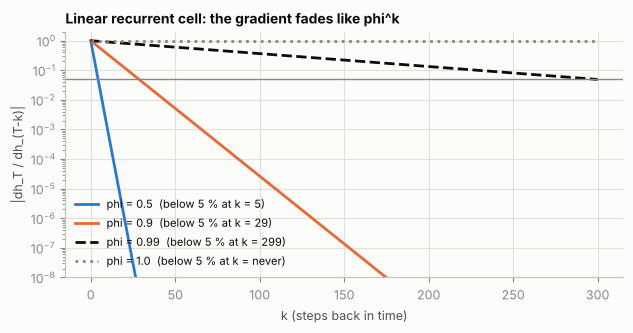

In [22]:
# Figure: the gradient of a linear recurrent cell fades like phi^k; phi = 1 keeps it constant (constant error flow).
ks = np.arange(0, 301)
fig, ax = plt.subplots(figsize=(6.4, 3.4))
for phi_, col, ls in ((0.5, BLUE, "-"), (0.9, ORANGE, "-"), (0.99, INK, "--"), (1.0, MUTED, ":")):
    mem = "never" if phi_ == 1 else f"{int(np.ceil(np.log(0.05) / np.log(phi_)))}"
    ax.plot(ks, phi_**ks, color=col, ls=ls, label=f"phi = {phi_}  (below 5 % at k = {mem})")
ax.axhline(0.05, color=MUTED, lw=1)
ax.set_yscale("log")
ax.set_ylim(1e-8, 2)
ax.set_xlabel("k (steps back in time)")
ax.set_ylabel("|dh_T / dh_(T-k)|")
ax.set_title("Linear recurrent cell: the gradient fades like phi^k")
ax.legend(loc="lower left")
fig.tight_layout()

**Lecture.** Différences finies et $\varphi^k$ coïncident aux chiffres affichés. Pour $\varphi=0.9$, le poids de Wold vaut 0.349, 0.0052 et $3\times10^{-5}$ à $k=10,50,100$ ; l'autocorrélation empirique (200 000 points) vaut 0.354, 0.006, 0.004 (écart de l'ordre de l'écart-type d'échantillonnage, environ 0.007 à $k=100$). Le gradient passe sous 5 % de sa valeur initiale en 5, 29 et 299 pas pour $\varphi=0.5$, $0.9$, $0.99$ (figure). *Prouve* : jacobienne $=\psi_k$ pour la récurrence linéaire. *Ne prouve pas* : rien sur l'entraînement d'un réseau non linéaire (pour $\tanh$, la jacobienne est un produit de facteurs $w(1-h_j^2)$, majoré par $|w|^k$ : heuristique).

**Direct ou récursif à plusieurs pas.** Un modèle à un pas, itéré $h$ fois, prévoit avec $\rho(1)^h$ ; une sortie *directe* à l'horizon $h$ (un coefficient par horizon, comme « climatologie + AR direct ») vise $\rho(h)$. Les deux coïncident si le processus est un AR(1), pas sinon. Test sur la chaîne à deux états de E2c, où $\rho_X(h)=0.8\cdot0.9^h$.

In [23]:
# 14d. Direct versus recursive multi-step forecasts on the two-regime chain of E2c, where rho_X(h) = 0.8 x 0.9^h.
x_m, _ = sim_markov_switching(
    300_000, [[0.95, 0.05], [0.05, 0.95]], [-2.0, 2.0], [1.0, 1.0], np.random.default_rng(SEED + 17)
)


def rho_hat(h):
    return np.corrcoef(x_m[:-h], x_m[h:])[0, 1]


HH = (1, 6, 24)
pd.DataFrame(
    {
        "direct: best linear coefficient, sample rho(h)": [rho_hat(h) for h in HH],
        "theory 0.8 x 0.9^h": [0.8 * 0.9**h for h in HH],
        "recursive: iterating the one-step coefficient, rho(1)^h": [rho_hat(1) ** h for h in HH],
    },
    index=[f"h = {h}" for h in HH],
).round(4)

,"direct: best linear coefficient, sample rho(h)",theory 0.8 x 0.9^h,"recursive: iterating the one-step coefficient, rho(1)^h"
h = 1,0.718,0.720,7.183e-01
h = 6,0.424,0.425,1.373e-01
h = 24,0.068,0.064,4.000e-04


**Lecture.** Le récursif sous-estime la mémoire d'un facteur 3 à $h=6$ (0.137 contre 0.424) et ne retient presque rien à $h=24$ ; le direct suit $0.8\cdot0.9^h$. *Prouve* : un modèle à un pas itéré n'a pas la mémoire d'un processus à état latent. *Ne prouve pas* : que ce soit le cas d'un réseau récurrent riche, qui peut porter un état.

### 8.3 Mélanges de Markov et densité de mélange

En E2c, la loi prédictive à $h=24$ est un mélange, mal représenté par une gaussienne. Un *réseau à densité de mélange* [Bis94] sort des poids $\pi_k(x)$, des moyennes $\mu_k(x)$ et des échelles $\sigma_k(x)$ ; entraîné par log-vraisemblance, il estime $\sum_k\pi_k(x)N(\mu_k(x),\sigma_k(x)^2)$. Les poids attendus sont les probabilités filtrées propagées $\sum_i\mathbb P(s_t=i\mid\mathcal F_t)(P^h)_{ik}$ ([annexe P4](https://github.com/GalaxiLir/stats-to-deeplearning/blob/main/01-ts-uncertainty/docs/00b_annexe_technique.md#P4)). **Attente, non testée** : un tel réseau devrait rattraper l'oracle de E2c au niveau 50 % là où le gaussien AR couvre 0.316.

### 8.4 OU, double puits et diffusion

L'OU est le processus de bruitage le plus simple des modèles génératifs à diffusion [SSKKEP21] (forme exacte de leurs EDS non relue). Si la loi initiale est $N(m_0,v_0)$, la transition de l'OU donne à l'instant $t$ la loi $N\big(m_0e^{-\kappa t},\ v_0e^{-2\kappa t}+\sigma^2\frac{1-e^{-2\kappa t}}{2\kappa}\big)$, de score linéaire $-(x-m_t)/v_t$ : le score est explicite. Pour le double puits, la loi à l'instant $t$ n'est pas gaussienne : le score doit être *appris* par un réseau, objet de la reproduction « diffusion » du plan. Aucune cellule n'entraîne de score ici.

### 8.5 Précautions pour la suite

- Un réseau a deux sources d'aléa : les données (déjà couvertes par les $R$ trajectoires indépendantes) et l'initialisation et l'ordre des lots (graines). L'erreur-type doit couvrir les deux.
- Les hyperparamètres se choisissent sur un bloc situé *entre* l'apprentissage et le test, jamais sur le test (H4).
- Les lignes de base de ce notebook doivent rester dans toute comparaison : [Zen23] (résumé lu) rapportent qu'un modèle linéaire simple rivalise avec des Transformers sur la prévision à long horizon.
- **Programme, attentes non testées** : réseau (perceptron multicouche, puis GRU) sur les générateurs de E1, E2, E2c avec les pertes quadratique, pinball et log-vraisemblance ; en E1 il devrait rejoindre « climatologie + AR » sans battre l'oracle ; en E2 une sortie quantile devrait réduire l'écart de couverture par tercile ; en E2c une sortie à mélange devrait rattraper l'oracle au niveau 50 %.

## Références

Même liste et mêmes statuts que le §9 du document compagnon. Pour chaque référence : ce que la source établit (en italique), puis son statut. ✔ texte lu ; ✔ résumé lu ; ◐ fiche seule ; ◐ ouvrage non relu ; *non vérifié* (cité de mémoire).

- **[BCRT23]** Barber, R. F., Candès, E. J., Ramdas, A. et Tibshirani, R. J. (2023). Conformal prediction beyond exchangeability. *Ann. Statist.* 51(2), 816–845. doi:10.1214/23-AOS2276 — *Garanties de couverture sans échangeabilité, par quantiles pondérés et randomisation ; le cas glissant comme cas particulier n'est pas vérifié* — ✔ résumé lu
- **[BSB05]** Benth, F. E. et Šaltytė Benth, J. (2005). Stochastic modelling of temperature variations with a view towards weather derivatives. *Appl. Math. Finance* 12(1), 53–85 — *Température : moyenne et volatilité saisonnières, bruit de type OU piloté par un processus de Lévy hyperbolique généralisé* — ✔ résumé lu
- **[BD91]** Brockwell, P. J. et Davis, R. A. *Time Series: Theory and Methods*, 2e éd. Springer — *Ouvrage de référence (causalité, inversibilité, Wold) ; énoncés de T1 non comparés au texte* — ◐ ouvrage non relu
- **[BJRL15]** Box, G. E. P., Jenkins, G. M., Reinsel, G. C. et Ljung, G. M. (2015). *Time Series Analysis: Forecasting and Control*, 5e éd. Wiley — *Ouvrage de référence sur ARIMA et SARIMA* — ◐ ouvrage non relu
- **[Bol86]** Bollerslev, T. (1986). Generalized autoregressive conditional heteroskedasticity. *J. Econometrics* 31(3), 307–327 — *Définit le GARCH ; conditions de stationnarité et structure d'autocorrélation. Le kurtosis et la forme ARMA du carré sont redémontrés en T3, non comparés au texte* — ✔ résumé lu
- **[CD05]** Campbell, S. D. et Diebold, F. X. (2005). Weather forecasting for weather derivatives. *J. Amer. Statist. Assoc.* 100, 6–16 (NBER w10141) — *Dynamique de la moyenne et de la variance conditionnelles de la température quotidienne* — ✔ résumé lu
- **[DF79]** Dickey, D. A. et Fuller, W. A. (1979). Distribution of the estimators for autoregressive time series with a unit root. *J. Amer. Statist. Assoc.* 74, 427–431 (volume et pages de mémoire) — *Lois limites de l'estimateur et du test $t$ sous $\rho=1$* — ◐ titre et résumé lus ; volume et pages non vérifiés
- **[DK12]** Durbin, J. et Koopman, S. J. *Time Series Analysis by State Space Methods*, 2e éd. Oxford University Press — *Ouvrage de référence sur l'espace d'état et le filtre de Kalman* — ◐ ouvrage non relu
- **[DP88]** Durlauf, S. N. et Phillips, P. C. B. (1988). Trends versus random walks in time series analysis. *Econometrica* 56(6), 1333–1354 — *Fonctionnelles browniennes pour la comparaison tendances et marches aléatoires* — ◐ résumé lu ; ordre des auteurs non confirmé par la fiche
- **[EG87]** Engle, R. F. et Granger, C. W. J. (1987). Co-integration and error correction: representation, estimation, and testing. *Econometrica* 55(2), 251–276 (pages de mémoire) — *Cointégration : combinaison stationnaire de séries intégrées* — ◐ résumé lu ; pages non vérifiées
- **[Eng82]** Engle, R. F. (1982). Autoregressive conditional heteroscedasticity with estimates of the variance of United Kingdom inflation. *Econometrica* 50(4), 987–1007 — *Introduit l'ARCH, appliqué à la variance de l'inflation britannique* — ✔ résumé lu
- **[GBR07]** Gneiting, T., Balabdaoui, F. et Raftery, A. E. (2007). Probabilistic forecasts, calibration and sharpness. *J. R. Stat. Soc. B* 69(2), 243–268 — *Distingue calibration et finesse ; maximiser la finesse sous calibration* — ✔ résumé lu
- **[GC21]** Gibbs, I. et Candès, E. (2021). Adaptive conformal inference under distribution shift. NeurIPS 34 ; arXiv:2106.00170 — *ACI : ajustement en ligne du niveau, couverture de long terme malgré les changements de loi ; règle de mise à jour non relue* — ✔ résumé lu
- **[GJ80]** Granger, C. W. J. et Joyeux, R. (1980). An introduction to long-memory time series models and fractional differencing. *J. Time Ser. Anal.* 1(1), 15–29 — *Modèles à mémoire longue, différenciation fractionnaire* — ◐ fiche seule
- **[GN74]** Granger, C. W. J. et Newbold, P. (1974). Spurious regressions in econometrics. *J. Econometrics* 2(2), 111–120 — *Simulations : régressions de marches aléatoires indépendantes, $R^2$ élevé, DW faible, rejets fréquents ; ne démontre pas l'asymptotique ; ne cite pas Yule (1926)* — ✔ texte lu
- **[GR07]** Gneiting, T. et Raftery, A. E. (2007). Strictly proper scoring rules, prediction, and estimation. *J. Amer. Statist. Assoc.* 102(477), 359–378. doi:10.1198/016214506000001437 — *Propreté des règles (pinball, score d'intervalle) ; CRPS comme intégrale de scores de Brier ; orientation du score non confirmée dans le texte publié* — ✔ texte lu (version rapport technique)
- **[Ham89]** Hamilton, J. D. (1989). A new approach to the economic analysis of nonstationary time series and the business cycle. *Econometrica* 57(2), 357–384 — *Régimes de Markov appliqués au cycle économique* — ✔ résumé lu
- **[HA18]** Hyndman, R. J. et Athanasopoulos, G. (2018). *Forecasting: Principles and Practice*, 2e éd. OTexts, §3.4 — *Échelle du MASE (erreur de la naïve)* — ✔ texte lu (§3.4)
- **[HK06]** Hyndman, R. J. et Koehler, A. B. (2006). Another look at measures of forecast accuracy. *Int. J. Forecasting*. doi:10.1016/j.ijforecast.2006.03.001 — *Définit le MASE* — ◐ fiche seule
- **[Hos81]** Hosking, J. R. M. (1981). Fractional differencing. *Biometrika* 68(1), 165–176 — *Fonction d'autocorrélation de l'ARFIMA ; constante exacte à relire* — ◐ fiche seule (auteur non affiché)
- **[HS97]** Hochreiter, S. et Schmidhuber, J. (1997). Long short-term memory. *Neural Computation* 9(8), 1735–1780 — *Cellule à flux d'erreur constant contre le gradient évanescent* — ✔ résumé lu
- **[Bis94]** Bishop, C. M. (1994). Mixture density networks. Rapport technique NCRG/94/004, Aston University — *Réseau dont la sortie est un mélange de lois* — ◐ fiche seule
- **[BSF94]** Bengio, Y., Simard, P. et Frasconi, P. (1994). Learning long-term dependencies with gradient descent is difficult. *IEEE Trans. Neural Networks* 5(2), 157–166 — *Difficulté de l'apprentissage de dépendances longues par descente de gradient (d'après le titre)* — ◐ fiche seule
- **[KB78]** Koenker, R. et Bassett, G. (1978). Regression quantiles. *Econometrica* 46(1) — *Définit la régression quantile (la preuve du minimiseur est donnée ici)* — ◐ fiche seule ; pages non vérifiées
- **[KP92]** Kloeden, P. E. et Platen, E. *Numerical Solution of Stochastic Differential Equations*. Springer — *Ouvrage de référence sur Euler–Maruyama* — ◐ ouvrage non relu
- **[KPSS92]** Kwiatkowski, D., Phillips, P. C. B., Schmidt, P. et Shin, Y. (1992). Testing the null hypothesis of stationarity against the alternative of a unit root. *J. Econometrics* 54, 159–178 — *$H_0$ : stationnarité ; faible puissance des tests usuels de racine unitaire (introduction)* — ✔ texte lu (introduction)
- **[KSC98]** Kim, S., Shephard, N. et Chib, S. (1998). Stochastic volatility: likelihood inference and comparison with ARCH models. *Rev. Econ. Stud.* 65(3), 361–393 — *Inférence par vraisemblance pour la volatilité stochastique* — ◐ fiche seule ; notice non reconfirmée
- **[KV05]** Kiefer, N. M. et Vogelsang, T. J. (2005). A new asymptotic theory for heteroskedasticity-autocorrelation robust tests. *Econometric Theory* 21(6), 1130–1164 — *Distorsions de taille des tests HAC selon la fenêtre* — ✔ résumé lu
- **[LGRTW18]** Lei, J., G'Sell, M., Rinaldo, A., Tibshirani, R. J. et Wasserman, L. (2018). Distribution-free predictive inference for regression. *J. Amer. Statist. Assoc.* 113(523), 1094–1111 — *Couverture en échantillon fini pour tout estimateur de régression (conforme séparé)* — ✔ résumé lu
- **[NK81]** Nelson, C. R. et Kang, H. (1981). Spurious periodicity in inappropriately detrended time series. *Econometrica* 49(3), 741–751 (pages de mémoire) — *Retirer une tendance déterministe à une marche aléatoire crée des cycles apparents* — ◐ résumé lu ; pages non vérifiées
- **[NP82]** Nelson, C. R. et Plosser, C. I. (1982). Trends and random walks in macroeconomic time series. *J. Monetary Econ.* 10(2), 139–162 — *Pose la question tendance déterministe ou stochastique pour des séries macroéconomiques* — ✔ résumé lu
- **[NW87]** Newey, W. K. et West, K. D. (1987). A simple, positive semi-definite, heteroskedasticity and autocorrelation consistent covariance matrix. *Econometrica* 55(3), 703–708 — *Estimateur HAC semi-défini positif et convergent ; poids de Bartlett non relus* — ✔ résumé lu
- **[Per89]** Perron, P. (1989). The Great Crash, the oil price shock, and the unit root hypothesis. *Econometrica* 57(6), 1361–1401 — *Sous une rupture déterministe, les tests de racine unitaire ne rejettent pas, même asymptotiquement* — ✔ résumé lu
- **[Phi86]** Phillips, P. C. B. (1986). Understanding spurious regressions in econometrics. *J. Econometrics* 33(3), 311–340 — *Asymptotique de la régression fallacieuse (fonctionnelles browniennes)* — ✔ résumé lu
- **[Ric81]** Richardson, C. W. (1981). Stochastic simulation of daily precipitation, temperature, and solar radiation. *Water Resour. Res.* 17(1), 182–190. doi:10.1029/wr017i001p00182 — *Générateur de temps* — ◐ fiche seule
- **[RPC19]** Romano, Y., Patterson, E. et Candès, E. (2019). Conformalized quantile regression. NeurIPS 32 ; arXiv:1905.03222 — *CQR : conforme appliqué à la régression quantile* — ✔ résumé lu
- **[RW06]** Rasmussen, C. E. et Williams, C. K. I. (2006). *Gaussian Processes for Machine Learning*. MIT Press — *Ouvrage de référence sur les noyaux, dont Matérn* — ◐ ouvrage non relu (site consulté)
- **[Sal20]** Salinas, D., Flunkert, V., Gasthaus, J. et Januschowski, T. (2020). DeepAR: probabilistic forecasting with autoregressive recurrent networks. *Int. J. Forecasting* 36(3), 1181–1191 (volume et pages de mémoire) — *Réseau récurrent à sortie probabiliste, entraîné par vraisemblance* — ◐ fiche seule ; volume et pages non vérifiés
- **[SD84]** Said, S. E. et Dickey, D. A. (1984). Testing for unit roots in autoregressive-moving average models of unknown order. *Biometrika* 71(3), 599–607 — *ADF : approximation d'un ARMA par un autorégressif ; retards ajoutés* — ◐ résumé lu ; notice non reconfirmée
- **[SSKKEP21]** Song, Y., Sohl-Dickstein, J., Kingma, D. P., Kumar, A., Ermon, S. et Poole, B. (2021). Score-based generative modeling through stochastic differential equations. ICLR 2021 ; arXiv:2011.13456 — *EDS directe vers le bruit, EDS rétrograde exigeant le score ; forme exacte de la EDS « VP » non vérifiée* — ✔ résumé lu
- **[Tay00]** Taylor, J. W. (2000). A quantile regression neural network approach to estimating the conditional density of multiperiod returns. *J. Forecasting* 19(4), 299–311 — *Réseau à sortie quantile (d'après le titre)* — ◐ fiche seule
- **[TL80]** Tong, H. et Lim, K. S. (1980). Threshold autoregression, limit cycles and cyclical data. *J. R. Stat. Soc. B* 42(3), 245–292 — *Modèles autorégressifs à seuil* — ◐ fiche seule
- **[UO30]** Uhlenbeck, G. E. et Ornstein, L. S. (1930). On the theory of the Brownian motion. *Phys. Rev.* 36, 823 — *Théorie du mouvement brownien (OU)* — ◐ fiche seule (page finale non lue)
- **[WW99]** Wilks, D. S. et Wilby, R. L. (1999). The weather generation game: a review of stochastic weather models. *Prog. Phys. Geogr.* 23(3), 329–357 — *Revue des générateurs de temps* — ◐ fiche seule
- **[Zen23]** Zeng, A., Chen, M., Zhang, L. et Xu, Q. (2023). Are transformers effective for time series forecasting? AAAI 2023 ; arXiv:2205.13504 — *Un modèle linéaire simple rivalise avec des Transformers sur la prévision à long horizon (résumé)* — ✔ résumé lu

Référence de contexte, non citée dans le texte : Murphy, A. H. (1992). Climatology, persistence, and their linear combination as standards of reference in skill scores. *Weather and Forecasting* 7(4), 692–698 (fiche lue ; contenu non lu).

**Repères historiques et résultats classiques cités de mémoire, non vérifiés** : Legendre et Gauss (moindres carrés, vers 1805–1809) ; Langevin (1908) ; Yule (1926, corrélations absurdes ; 1927, AR(2) et taches solaires) ; Slutsky (1937) ; Wold (1938, décomposition) ; Kramers (1940) ; Hurst (1951) ; Hasselmann (1976) ; Vasicek (1977) ; Benzi, Sutera et Vulpiani (1982) ; théorème ergodique de Birkhoff ; principe d'invariance de Donsker ; cohérence de la quasi-vraisemblance GARCH ; identité du CRPS ; formule exacte de $\rho(h)$ pour l'ARFIMA ; forme de la statistique KPSS.